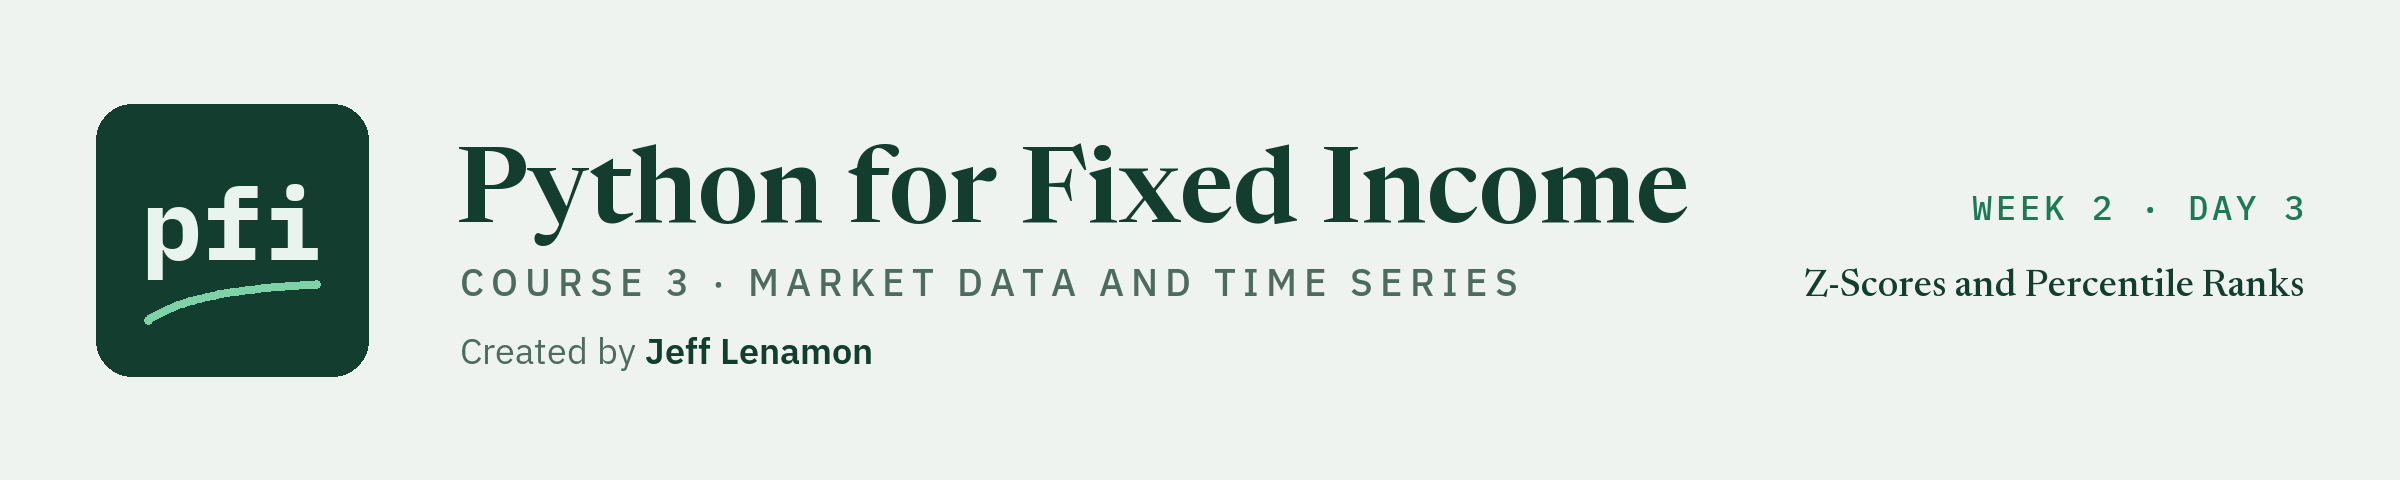

# Z-Scores and Percentile Ranks

Week 2, Day 3. Where does today's level sit in its own recent history? Today: the z-score and the percentile rank over a trailing window, each defined in writing, tested against Excel, and proved to use no future data, and the words that describe a level without forecasting it.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day3/08_z_scores_and_percentile_ranks.ipynb)

Yesterday, day 7, measured how much a series moves: rolling volatility of daily changes in bp, over a trailing window of rows, with `assert_no_lookahead` to prove the window never reaches past its own date. Today asks a different question about a **level**: compared with its own last year, where does today's number sit?

It is the question behind the line on many morning notes: "the 10-year is near the top of its one-year range." Two measures make that sentence precise:

* The **z-score**: how many standard deviations today's value is from the mean of its window.
* The **percentile rank**: what share of the window is at or below today's value.

Today you will:

1. Look at the 10 Yr's last 252 market days and say where today sits, three ways.
2. Write `rolling_zscore`, and see that leaving today out of its own window changes the number.
3. Write `rolling_percentile_rank`, count ties, and meet a floating point trap that makes pandas and Excel disagree.
4. See that Excel's `PERCENTRANK.INC` measures something else.
5. Compute both measures on the 10 Yr and on 2s10s for 2026, checked against Excel and tested for lookahead.
6. Sort the words that describe a level from the words that forecast one.

**The rule for today, and for the rest of the course.** A z-score and a percentile rank say where today's value sits in its own recent history. That is all they say. This course never calls them a signal, never calls a level cheap, rich, or stretched, never says a level is due to revert, and never draws a line (such as "above 2") as if crossing it meant something. Section 8.6 makes the rule a table.

The setup cell is the same every day: a fresh work folder, today's three data files (the Treasury file, Excel's reference rows, and the FRED-format sample that day 2's tests read), and `marketdata.py` and `test_marketdata.py` as they stood at the end of day 7. Today has no live cell: every number comes from the Treasury file, so it needs no key.

Q. Set up today's work folder and copy today's three data files into it.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course03_market_data/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "dotenv": "python-dotenv==1.2.4",
    "requests": "requests==2.34.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

9 packages checked, all present


In [2]:
# today's setup: modules, the course data, a fresh work folder, and the constants the live cells use
import importlib
import os
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

import pandas as pd

# the course's chart style, set once here so every chart in the notebook looks the same
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (9, 5),          # width and height of a chart, in inches
    "figure.dpi": 110,                 # sharpness on screen
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    # the course greens, then a grey, for the first four lines or bars of a chart
    "axes.prop_cycle": plt.cycler(color=["#123d2f", "#1c7a57", "#7fd1a8", "#8c8c8c"]),
    "axes.grid": True,                 # light gridlines, as in an Excel chart
    "grid.color": "#dddddd",
    "axes.spines.top": False,          # no box line above or to the right of the plot
    "axes.spines.right": False,
})

# three packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("pytest", "pytest"), ("requests", "requests"), ("dotenv", "python-dotenv")]:
    try:
        importlib.import_module(module_name)
    except ImportError:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.") from None
import pytest
import requests

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()
data_folder = RAW_DATA if on_github else str(local_data) + os.sep

# 2. your own key file: in your my_bondmath folder, outside every repository. Its path is never printed.
ENV_FILE = Path.home() / "projects" / "my_bondmath" / ".env"

# 3. the two constants of the live cells
NO_KEY_MESSAGE = "Live cell skipped: no FRED key was found. Every other cell runs without one."
# ICE BofA and Moody's values stay off the screen unless you set this to True, on your own machine only
SHOW_LICENSED_VALUES = False

# 4. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course3_08_"))
os.chdir(work)

# 5. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv", "course3_excel_reference.csv", "course3_fred_format_dgs10.json"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES) or 'none'}")
print(f"pytest {pytest.__version__}, requests {requests.__version__}")

Work folder: pfi_course3_08_7gl8csjo, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv, course3_excel_reference.csv, course3_fred_format_dgs10.json
pytest 9.1.1, requests 2.34.2


Q. Write `bondmath.py`, the reference copy of the module you finished in Course 2.

It is written into the work folder so that every notebook runs, in Colab too, whether or not you took Course 2. To use your own copy instead, run this line in a new cell after the next one:

```python
shutil.copy(Path.home() / "projects" / "my_bondmath" / "bondmath.py", work)
```

The saved outputs of this notebook always come from the reference copy.

In [3]:
%%writefile bondmath.py
"""bondmath: bond math for fixed-rate bullet bonds, checked against Excel.

Written day by day in Python for Fixed Income, Course 2: Bond Math.

Units, the same in every function:
- coupon_pct and yield_pct are annual rates in percent: 7.0 means 7 percent. Excel takes decimals (0.07).
- Prices and accrued interest are per 100 of face.
- Durations are in years, convexity in years squared, spreads in basis points.
- frequency is the number of coupons (or compounding periods) a year: 1, 2, or 4.
- basis is the day count: "30/360" (Excel basis 0) or "ACT/ACT" (Excel basis 1).
- Dates are datetime.date values.
"""
import calendar  # month lengths, used from week 2
from datetime import date  # calendar dates, used from week 2


def future_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Grow an amount at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount x (1 + rate / frequency) ** (frequency x years).
    Excel: =FV(rate_pct/100/frequency, frequency*years, 0, -amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # grow the amount over every period
    return amount * (1 + period_rate) ** periods


def present_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Discount an amount due in `years` at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount / (1 + rate / frequency) ** (frequency x years).
    Returns a positive number for a positive amount. Excel's PV returns the same number with a
    minus sign: =-PV(rate_pct/100/frequency, frequency*years, 0, amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # discount the amount over every period
    return amount / (1 + period_rate) ** periods


def cash_flows(coupon_pct: float, years: float, frequency: int = 2) -> list[tuple[float, float]]:
    """The cash flows of a bullet bond bought on a coupon date.

    Units: coupon_pct in percent of face a year, years in years. Each cash flow is per 100 of face.
    Convention: one coupon of coupon_pct / frequency every 1 / frequency years, and 100 back with
    the last coupon. Returns a list of (time in years, cash flow) pairs, earliest first.
    Raises ValueError unless years x frequency is a whole number of periods.
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # count the coupon periods and check they are whole
    periods = years * frequency
    if periods <= 0 or abs(periods - round(periods)) > 1e-9:
        raise ValueError(f"{years} years is not a whole number of periods at frequency {frequency}")
    periods = round(periods)
    # each coupon is the annual coupon split into equal parts
    coupon = coupon_pct / frequency
    flows = []
    for k in range(1, periods + 1):
        # the time of payment k, in years
        time_years = k / frequency
        # the last payment also returns the face of 100
        amount = coupon + 100 if k == periods else coupon
        flows.append((time_years, amount))
    return flows


def price_from_yield(coupon_pct: float, yield_pct: float, years: float, frequency: int = 2) -> float:
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)
    """
    # the yield for one period, as a decimal
    period_yield = yield_pct / 100 / frequency
    price = 0.0
    for time_years, amount in cash_flows(coupon_pct, years, frequency):
        # discount each cash flow by one factor per period until it is paid
        price += amount / (1 + period_yield) ** (time_years * frequency)
    return price


def convert_yield(yield_pct: float, from_frequency: int, to_frequency: int) -> float:
    """The same yield restated at another compounding frequency.

    Units: yield_pct in percent a year; the result is in percent a year.
    Convention: both rates grow 100 to the same amount in one year.
    Excel: convert_yield(y, f, 1) is =EFFECT(y/100, f)*100, and convert_yield(y, 1, f) is =NOMINAL(y/100, f)*100.
    """
    # stop on a frequency the course does not use
    for frequency in (from_frequency, to_frequency):
        if frequency not in (1, 2, 4):
            raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # how much 1 grows to in one year at the original frequency
    growth_one_year = (1 + yield_pct / 100 / from_frequency) ** from_frequency
    # the rate per period at the new frequency that gives the same growth
    period_rate = growth_one_year ** (1 / to_frequency) - 1
    # back to an annual rate in percent
    return period_rate * to_frequency * 100


def yield_from_price(coupon_pct: float, price: float, years: float, frequency: int = 2) -> float:
    """Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in percent.
    Convention: the yield, compounded `frequency` times a year, at which price_from_yield equals price.
    The search runs between -5 and 100 percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Excel: =RATE(frequency*years, coupon_pct/frequency, -price, 100)*frequency, then x 100.
    """
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price_from_yield(coupon_pct, low_pct, years, frequency)
    lowest_price = price_from_yield(coupon_pct, high_pct, years, frequency)
    if not lowest_price <= price <= highest_price:
        raise ValueError(f"price {price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price_from_yield(coupon_pct, mid_pct, years, frequency) > price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def add_months(d: date, months: int) -> date:
    """Move a date by whole months, keeping the day of the month where the month allows it.

    Units: d is a date, months a whole number (negative moves back).
    Convention: the day is clamped to the length of the new month, so 31 August minus 6 months is
    28 February (29 February in a leap year). Excel: =EDATE(d, months)
    """
    # count months from year 0 so the year and month come out of one division
    month_index = d.year * 12 + (d.month - 1) + months
    year, month_zero_based = divmod(month_index, 12)
    month = month_zero_based + 1
    # the number of days in the new month
    days_in_month = calendar.monthrange(year, month)[1]
    # keep the day, or use the last day of a shorter month
    return date(year, month, min(d.day, days_in_month))


def coupon_dates(settlement: date, maturity: date, frequency: int = 2) -> list[date]:
    """The previous coupon date, then every coupon date left through maturity.

    Units: dates. Convention: coupon dates are counted back from maturity in steps of 12 / frequency
    months, each one computed from maturity directly, so a 31st never drifts to the 28th. If maturity
    is the last day of its month, every coupon date is the last day of its month (Excel's rule).
    The previous coupon date is the last one on or before settlement.
    So [0] is Excel's COUPPCD, [1] is COUPNCD, and len - 1 is COUPNUM.
    """
    # stop on bad input
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # months between coupons
    step_months = 12 // frequency
    # does the bond mature on the last day of a month?
    month_end = maturity.day == calendar.monthrange(maturity.year, maturity.month)[1]
    dates = []
    k = 0
    while True:
        # coupon k steps back from maturity, computed from maturity itself
        coupon_date = add_months(maturity, -k * step_months)
        if month_end:
            # the month-end rule: move to the last day of that month
            last_day = calendar.monthrange(coupon_date.year, coupon_date.month)[1]
            coupon_date = date(coupon_date.year, coupon_date.month, last_day)
        dates.append(coupon_date)
        # stop once we reach the previous coupon date
        if coupon_date <= settlement:
            break
        k += 1
    # earliest first
    dates.reverse()
    return dates


def days_30_360(start: date, end: date) -> int:
    """Days from start to end on the US 30/360 basis, as Excel's COUPDAYBS and YEARFRAC(..., 0) count them.

    Units: dates in, whole days out. Every month counts as 30 days and every year as 360.
    Convention, with D1 the start day and D2 the end day:
    1. If start is the last day of February, D1 = 30.
    2. If start and end are both the last day of February, D2 = 30.
    3. If D1 is 31, D1 = 30.
    4. If D2 is 31 and the start day was 30 or 31, D2 = 30. (Excel looks at the start date's own
       day here, so a start on 28 February and an end on the 31st keeps D2 = 31.)
    Days = 360 x (Y2 - Y1) + 30 x (M2 - M1) + (D2 - D1).
    Excel's DAYS360 uses different February rules and is not the same count.
    """
    d1, d2 = start.day, end.day
    start_is_feb_end = start.month == 2 and start.day == calendar.monthrange(start.year, 2)[1]
    end_is_feb_end = end.month == 2 and end.day == calendar.monthrange(end.year, 2)[1]
    # rule 1: the last day of February counts as the 30th
    if start_is_feb_end:
        d1 = 30
    # rule 2: both dates on the last day of February
    if start_is_feb_end and end_is_feb_end:
        d2 = 30
    # rule 3: a 31st start counts as the 30th
    if start.day == 31:
        d1 = 30
    # rule 4: a 31st end counts as the 30th when the start day was 30 or 31
    if end.day == 31 and start.day >= 30:
        d2 = 30
    return 360 * (end.year - start.year) + 30 * (end.month - start.month) + (d2 - d1)


def coupon_period_days(settlement: date, maturity: date, frequency: int = 2,
                       basis: str = "30/360") -> tuple[int, int, int]:
    """Day counts of the coupon period that holds settlement: (A, E, DSC).

    Units: whole days.
    A is days from the previous coupon to settlement (Excel COUPDAYBS).
    E is days in the coupon period: 360 / frequency under 30/360 (Excel COUPDAYS), and the actual days
    from the previous to the next coupon under ACT/ACT.
    DSC is days from settlement to the next coupon, as Excel's PRICE uses it: E - A under 30/360
    (this can differ from COUPDAYSNC near the end of February), actual days under ACT/ACT.
    """
    # stop on a basis the course does not use (coupon_dates checks frequency and dates)
    if basis not in ("30/360", "ACT/ACT"):
        raise ValueError(f'basis must be "30/360" or "ACT/ACT", not {basis!r}')
    # the previous and next coupon dates
    dates = coupon_dates(settlement, maturity, frequency)
    previous_coupon, next_coupon = dates[0], dates[1]
    if basis == "30/360":
        # 30/360: A by the 30/360 rules, a fixed period length, and DSC as what is left of it
        days_accrued = days_30_360(previous_coupon, settlement)
        days_in_period = 360 // frequency
        days_to_next = days_in_period - days_accrued
    else:
        # ACT/ACT: every count is actual calendar days
        days_accrued = (settlement - previous_coupon).days
        days_in_period = (next_coupon - previous_coupon).days
        days_to_next = (next_coupon - settlement).days
    return days_accrued, days_in_period, days_to_next


def accrued_interest(settlement: date, maturity: date, coupon_pct: float, frequency: int = 2,
                     basis: str = "30/360") -> float:
    """Accrued interest the buyer pays the seller, per 100 of face.

    Units: coupon_pct in percent a year; the result is per 100 of face.
    Convention: coupon_pct / frequency x A / E, with A and E from coupon_period_days.
    Excel (30/360): =100*coupon_pct/100/frequency*COUPDAYBS(...)/COUPDAYS(...)
    """
    # A and E for this settlement
    days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
    # one coupon, times the share of the period that has passed
    return coupon_pct / frequency * days_accrued / days_in_period


def price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
          basis: str = "30/360") -> float:
    """Clean price per 100 of face on any settlement date, as Excel's PRICE.

    Units: coupon_pct and yield_pct in percent a year; the result is a clean price per 100 of face.
    Convention: yield compounded `frequency` times a year. w = DSC / E is the part of a period left
    until the next coupon. Dirty price = sum over the N coupons left of CF_k / (1 + y/f) ** (w + k).
    In the final coupon period (N = 1) Excel uses simple interest: dirty = (100 + CF) / (1 + w x y/f).
    Clean = dirty - accrued interest.
    Excel: =PRICE(settlement, maturity, coupon_pct/100, yield_pct/100, 100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    days_accrued, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    # coupons left, the fraction of a period to the next one, the period yield, and one coupon
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    if coupons_left == 1:
        # final period: simple interest on the last coupon and the face
        dirty = (100 + coupon) / (1 + w * period_yield)
    else:
        dirty = 0.0
        for k in range(coupons_left):
            # the last cash flow also returns the face
            cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
            dirty += cash_flow / (1 + period_yield) ** (w + k)
    # the quote is clean: take off the accrued interest
    return dirty - accrued_interest(settlement, maturity, coupon_pct, frequency, basis)


def dirty_price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                basis: str = "30/360") -> float:
    """Dirty (full, invoice) price per 100 of face: the clean price plus accrued interest.

    Units and convention as price(). Excel: =PRICE(...) + the accrued formula.
    """
    # clean price plus accrued interest
    return (price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
            + accrued_interest(settlement, maturity, coupon_pct, frequency, basis))


def yield_to_maturity(settlement: date, maturity: date, coupon_pct: float, clean_price: float,
                      frequency: int = 2, basis: str = "30/360") -> float:
    """Yield in percent from a clean price on any settlement date, by bisection, as Excel's YIELD x 100.

    Units: coupon_pct in percent a year, clean_price per 100 of face; the result is in percent a year.
    Convention: the yield at which price() equals clean_price. The search runs between -5 and 100
    percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Final coupon period: Excel's YIELD uses a formula instead of a search, with DSR, the days from
    settlement to maturity, counted by days_30_360 under 30/360 (actual days under ACT/ACT):
    yield = ((100 + CF) - dirty) / dirty x frequency x E / DSR. Under 30/360 DSR can differ from the
    E - A that PRICE uses, so in those cases YIELD does not return the yield PRICE was given.
    Excel: =YIELD(settlement, maturity, coupon_pct/100, clean_price, 100, frequency, basis)*100
    """
    # final coupon period: Excel's formula (coupon_dates and coupon_period_days check the inputs)
    if len(coupon_dates(settlement, maturity, frequency)) - 1 == 1:
        days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
        if basis == "30/360":
            days_to_maturity = days_30_360(settlement, maturity)
        else:
            days_to_maturity = (maturity - settlement).days
        coupon = coupon_pct / frequency
        # the dirty price paid, and what comes back at maturity
        paid = clean_price + coupon * days_accrued / days_in_period
        received = 100 + coupon
        # the simple return over the days left, made annual, in percent
        return (received - paid) / paid * frequency * days_in_period / days_to_maturity * 100
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price(settlement, maturity, coupon_pct, low_pct, frequency, basis)
    lowest_price = price(settlement, maturity, coupon_pct, high_pct, frequency, basis)
    if not lowest_price <= clean_price <= highest_price:
        raise ValueError(f"price {clean_price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price(settlement, maturity, coupon_pct, mid_pct, frequency, basis) > clean_price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def macaulay_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Macaulay duration in years: the present-value weighted average time of the cash flows.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: t_k = (w + k) / frequency years, PV_k = CF_k / (1 + y/f) ** (w + k), and
    duration = sum of t_k x PV_k / sum of PV_k. In the final period this is DSC / E / frequency.
    Excel: =DURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, weighted_time = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow, its time in years, and its present value
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        pv = cash_flow / (1 + period_yield) ** (w + k)
        total_pv += pv
        weighted_time += time_years * pv
    # the weighted average time
    return weighted_time / total_pv


def modified_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Modified duration in years: the percent price change for a 1-point (100 bp) change in yield.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: Macaulay duration / (1 + y / frequency), with y = yield_pct / 100.
    Excel: =MDURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # divide Macaulay duration by one plus the period yield
    period_yield = yield_pct / 100 / frequency
    return macaulay_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis) / (1 + period_yield)


def dv01(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
         basis: str = "30/360") -> float:
    """DV01: price points per 100 of face for a 1 basis point fall in yield, positive for a long position.

    Units: coupon_pct and yield_pct in percent a year; the result is in price points per 100 of face per bp.
    Convention: modified duration x dirty price x 0.0001. Position DV01 in dollars = dv01 x par / 100.
    Excel: =MDURATION(...)*(PRICE(...)+accrued)/10000
    """
    # modified duration times the dirty price, for one basis point (0.0001 as a decimal)
    duration_years = modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    return duration_years * full_price * 0.0001


def convexity(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
              basis: str = "30/360") -> float:
    """Convexity in years squared, unscaled (not divided by 100 or by 2).

    Units: coupon_pct and yield_pct in percent a year; the result is in years squared.
    Convention: (1 / P) x sum of CF_k x t_k x (t_k + 1/f) / (1 + y/f) ** (f t_k + 2), where
    t_k = (w + k) / f and P is the sum of the discounted cash flows. Price change estimate:
    dP / P = -D_mod x dy + 0.5 x convexity x dy ** 2, with dy in decimal.
    Excel has no convexity function; the check is a central difference on three PRICE cells.
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, curvature = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow and its time in years
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        # its present value, and its term in the convexity sum
        total_pv += cash_flow / (1 + period_yield) ** (w + k)
        curvature += (cash_flow * time_years * (time_years + 1 / frequency)
                      / (1 + period_yield) ** (frequency * time_years + 2))
    # divide by the price
    return curvature / total_pv


def interpolate_yield(tenor_years: float, curve_tenors: list[float], curve_yields_pct: list[float]) -> float:
    """Yield at any tenor by straight-line interpolation on a curve, flat beyond its ends.

    Units: tenors in years, yields in percent; the result is in percent.
    Convention: linear in yield against tenor between the two curve points around tenor_years. Below
    the first tenor the first yield is used, above the last tenor the last yield (as numpy.interp).
    Raises ValueError if the lists differ in length, are empty, or the tenors do not ascend.
    """
    # stop on a curve the function cannot read
    if len(curve_tenors) != len(curve_yields_pct) or len(curve_tenors) == 0:
        raise ValueError("curve_tenors and curve_yields_pct must be non-empty and the same length")
    for i in range(1, len(curve_tenors)):
        if curve_tenors[i] <= curve_tenors[i - 1]:
            raise ValueError(f"curve tenors must ascend: {curve_tenors[i - 1]} then {curve_tenors[i]}")
    # flat beyond the ends
    if tenor_years <= curve_tenors[0]:
        return curve_yields_pct[0]
    if tenor_years >= curve_tenors[-1]:
        return curve_yields_pct[-1]
    # find the two tenors around tenor_years
    i = 1
    while curve_tenors[i] < tenor_years:
        i += 1
    left_tenor, right_tenor = curve_tenors[i - 1], curve_tenors[i]
    left_yield, right_yield = curve_yields_pct[i - 1], curve_yields_pct[i]
    # move along the straight line between them
    slope = (right_yield - left_yield) / (right_tenor - left_tenor)
    return left_yield + slope * (tenor_years - left_tenor)


def years_to_maturity(settlement: date, maturity: date) -> float:
    """Years from settlement to maturity on the US 30/360 basis.

    Units: dates in, years out. Convention: days_30_360(settlement, maturity) / 360, the rule the
    holdings file used to read the curve. Excel: =YEARFRAC(settlement, maturity, 0)
    """
    # stop on dates in the wrong order
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # 30/360 days over a 360-day year
    return days_30_360(settlement, maturity) / 360


def spread_to_curve_bp(yield_pct: float, years: float, curve_tenors: list[float],
                       curve_yields_pct: list[float]) -> float:
    """Yield spread over a curve at the bond's own maturity, in basis points.

    Units: yield_pct and curve yields in percent, years and tenors in years; the result is in bp.
    Convention: (yield_pct - the curve interpolated at `years`) x 100. A yield spread at the same
    maturity, not an option-adjusted spread from a spot curve.
    """
    # the curve yield at the bond's maturity
    curve_yield_pct = interpolate_yield(years, curve_tenors, curve_yields_pct)
    # the gap in percent, times 100 basis points per percent
    return (yield_pct - curve_yield_pct) * 100


def spread_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                    basis: str = "30/360", bump_bp: float = 1.0) -> float:
    """Spread duration in years: the percent price change for a 100 bp move in the spread.

    Units: coupon_pct and yield_pct in percent a year, bump_bp in basis points; the result is in years.
    Convention: the yield is curve plus spread, so a spread move is a yield move. Central difference:
    (price at spread - bump minus price at spread + bump) / (2 x bump as a decimal) / dirty price.
    Accrued interest does not change with the spread, so clean price differences equal dirty ones.
    Excel: =(PRICE(...,yld-0.0001,...)-PRICE(...,yld+0.0001,...))/(2*0.0001)/(PRICE(...)+accrued)
    """
    # stop on a bump that cannot measure a slope
    if bump_bp <= 0:
        raise ValueError(f"bump_bp must be positive, not {bump_bp}")
    # the bump in percent (for yield_pct) and as a decimal (for the slope)
    bump_pct = bump_bp / 100
    bump_decimal = bump_bp / 10000
    # reprice with the spread down and up
    price_spread_down = price(settlement, maturity, coupon_pct, yield_pct - bump_pct, frequency, basis)
    price_spread_up = price(settlement, maturity, coupon_pct, yield_pct + bump_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    # the slope of price against spread, as a share of the dirty price
    return (price_spread_down - price_spread_up) / (2 * bump_decimal) / full_price


def dts(spread_duration_years: float, spread_bp: float) -> float:
    """Duration times spread (DTS), a published measure of spread risk.

    Units: spread duration in years, spread in basis points; the result is in years times bp.
    Convention: spread_duration_years x spread_bp.
    """
    # the product of the two
    return spread_duration_years * spread_bp


def weighted_average(values: list[float], weights: list[float]) -> float:
    """Weighted average of values.

    Units: the result has the units of the values; weights in any one unit (market value in dollars
    for a book). Convention: sum of value x weight / sum of weights. Excel: =SUMPRODUCT(values, weights)/SUM(weights)
    Raises ValueError if the lists differ in length or the weights sum to zero.
    """
    # stop on lists that do not line up, or weights with nothing in them
    if len(values) != len(weights):
        raise ValueError(f"{len(values)} values but {len(weights)} weights")
    total_weight = sum(weights)
    if total_weight == 0:
        raise ValueError("the weights sum to zero")
    # sum of value times weight
    total = 0.0
    for value, weight in zip(values, weights):
        total += value * weight
    return total / total_weight


def price_change_estimate(dirty_price: float, modified_duration: float, convexity: float, shift_bp: float) -> float:
    """Estimated change in price from duration and convexity, per 100 of face.

    Units: dirty_price per 100 of face, modified_duration in years, convexity in years squared,
    shift_bp in basis points (positive means yields up). The result is in price points per 100 of face.
    Convention: dirty_price x (-modified_duration x dy + 0.5 x convexity x dy ** 2), with dy = shift_bp / 10000.
    """
    # the yield change as a decimal
    dy = shift_bp / 10000
    # the duration term and the convexity term, times the price
    return dirty_price * (-modified_duration * dy + 0.5 * convexity * dy ** 2)

Writing bondmath.py


Q. Write `marketdata.py` and `test_marketdata.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile marketdata.py
"""marketdata: dated market series for fixed income, checked against Excel.

Written day by day in Python for Fixed Income, Course 3: Market Data and Time Series.

Conventions, the same in every function:
- A series has a DatetimeIndex named date: naive calendar dates (no time, no time zone), unique and ascending.
- Yields are in percent (5.29 means 5.29 percent), as Treasury and FRED publish them. Spreads are in basis points.
- Changes of yields and spreads are in basis points. Price changes are simple returns in percent.
- Windows are counted in observations (rows of the market calendar), trailing, and include the current row.
- A missing observation is NaN. It is dropped before any change or window is computed, never filled.
- A secret (an API key) is never printed, written to a file, or put in an error message.
"""
import os  # environment variables
from pathlib import Path  # file paths


def get_secret(name: str, env_file: str | Path) -> str:
    """Return a secret such as an API key, looked up in three places in a fixed order.

    Units: none; the secret is text. Convention: the first place that holds a non-empty value wins:
    1. the environment variable `name`;
    2. Colab's Secrets panel (google.colab.userdata), only when running in Colab;
    3. the .env file at `env_file`, read with dotenv.dotenv_values, which does not change os.environ.
    The value is returned and never printed. Raises RuntimeError naming the secret and the three places
    looked, never a value and never the full path of the file.
    """
    # 1. the environment: a variable set in PowerShell, or by the program that started Python
    value = os.environ.get(name)
    if value:
        return value

    # 2. Colab's Secrets panel: the import works only inside Colab
    try:
        from google.colab import userdata
    except ImportError:
        userdata = None
    if userdata is not None:
        try:
            value = userdata.get(name)
        # a secret that is not there, or one the notebook has not been given access to
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
            value = None
        if value:
            return value

    # 3. the .env file, imported here so Colab never needs python-dotenv
    env_path = Path(env_file)
    if env_path.is_file():
        from dotenv import dotenv_values
        value = dotenv_values(env_path).get(name)
        if value:
            return value

    # nothing found: say where we looked, with the file's name only (a full path shows a user name)
    raise RuntimeError(
        f"Secret {name} not found. Looked in: the environment variable {name}, "
        f"Colab's Secrets panel, and the file {env_path.name} given as env_file."
    )


import pandas as pd  # dated series, from day 2
import requests  # HTTP, from day 2

# FRED's endpoint for the observations of one series
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"


def fred_params(series_id: str, api_key: str, start: str | None = None, end: str | None = None) -> dict:
    """The query parameters for one request to FRED's series/observations endpoint.

    Units: start and end are dates as text, YYYY-MM-DD. Convention: JSON is asked for (file_type json);
    a start or end left as None is not sent, so FRED returns the series from its first or to its last date.
    Pure: builds a dict and sends nothing. The dict holds the key, so it is never printed.
    """
    # the three parameters every request needs
    params = {"series_id": series_id, "api_key": api_key, "file_type": "json"}
    # the optional date range
    if start is not None:
        params["observation_start"] = start
    if end is not None:
        params["observation_end"] = end
    return params


def parse_fred_observations(payload: dict, name: str) -> pd.Series:
    """Turn a FRED series/observations JSON answer into a float series.

    Units: as FRED publishes the series (percent for the Treasury and spread series).
    Convention: one value per observation, indexed by its date (a DatetimeIndex named date). FRED's
    missing marker "." becomes NaN and is kept: dropping it is a separate, visible step.
    Raises ValueError if the answer has no "observations" list.
    """
    # stop on an answer that is not a series/observations answer
    if "observations" not in payload:
        raise ValueError(f"the answer for {name} has no 'observations'; keys are {sorted(payload)}")
    observations = payload["observations"]
    # each date as a calendar date
    dates = pd.to_datetime([obs["date"] for obs in observations], format="%Y-%m-%d")
    # each value as a float; "." is FRED's mark for a day with no value, so it becomes NaN, never 0
    values = [float("nan") if obs["value"] == "." else float(obs["value"]) for obs in observations]
    series = pd.Series(values, index=dates, name=name, dtype="float64")
    series.index.name = "date"
    return series


def fred_series(series_id: str, api_key: str, start: str | None = None, end: str | None = None,
                timeout: float = 30) -> pd.Series:
    """Download one series from the FRED API: one GET with requests, then parse_fred_observations.

    Units: as FRED publishes the series. Convention: "." rows are kept as NaN, as parse_fred_observations.
    The only function in this module that uses the network.
    Errors never show the key or the URL (which holds the key):
    - it never calls response.raise_for_status(), whose message holds the full URL;
    - an answer other than HTTP 200 raises RuntimeError with the status and FRED's own error message;
    - a connection problem (requests.RequestException) raises RuntimeError naming only the exception class;
    - both are raised `from None`, so no chained traceback shows the original error and its URL.
    Raises RuntimeError if FRED answers with zero observations (FRED returns HTTP 200 with count 0 for a
    range the series does not cover).
    """
    # the request, sent once; the parameters (and the key) stay inside requests
    try:
        response = requests.get(FRED_URL, params=fred_params(series_id, api_key, start, end), timeout=timeout)
    except requests.RequestException as error:
        # the original message holds the URL with the key, so only the class name is kept
        raise RuntimeError(f"Request for {series_id} failed: {type(error).__name__}") from None

    # an answer other than 200: FRED puts its reason in "error_message"
    status = response.status_code
    if status != 200:
        try:
            error_message = response.json().get("error_message", "no error message")
        except ValueError:
            error_message = "the answer was not JSON"
        # FRED's messages do not echo the key; replace it anyway in case one ever does
        error_message = error_message.replace(api_key, "***")
        raise RuntimeError(f"FRED returned HTTP {status} for {series_id}: {error_message}") from None

    # parse, and stop on an empty answer
    series = parse_fred_observations(response.json(), series_id)
    if series.empty:
        raise RuntimeError(f"FRED returned no observations for {series_id} (start {start}, end {end})")
    return series


def _check_index(index: pd.Index, what: str) -> None:
    """Stop unless `index` is a DatetimeIndex with unique dates in ascending order.

    A helper for the functions below (the leading underscore marks it as not part of the module's API).
    """
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{what} must have a DatetimeIndex, not {type(index).__name__}")
    if not index.is_unique:
        raise ValueError(f"{what} has repeated dates, for example {index[index.duplicated()][0].date()}")
    if not index.is_monotonic_increasing:
        raise ValueError(f"{what} dates are not in ascending order")


def missing_weekdays(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    """The weekdays from the first date to the last that have no row.

    Units: dates. Convention: a weekday is Monday to Friday; no holiday calendar is used, so the result is
    every weekday the data skipped (holidays and any other closure). Weekends are never counted.
    Raises ValueError on an index that is not unique and ascending dates.
    """
    _check_index(index, "index")
    # every Monday to Friday in the span
    weekdays = pd.bdate_range(index[0], index[-1])
    # the ones with no row
    missing = weekdays.difference(index)
    missing.name = "date"
    return missing


def align(series: dict[str, pd.Series], how: str = "inner") -> pd.DataFrame:
    """Put several dated series side by side, one column each, joined on date.

    Units: each column keeps its own units. Convention: how="inner" keeps the dates every series has;
    how="outer" keeps every date any series has and leaves NaN where a series has no row. Nothing is filled.
    Raises ValueError for any other `how`, or for a series whose index is not unique ascending dates.
    """
    # stop on a join the course does not use
    if how not in ("inner", "outer"):
        raise ValueError(f"how must be 'inner' or 'outer', not {how!r}")
    for name, values in series.items():
        _check_index(values.index, name)
    # one column per series, named by its key
    frame = pd.concat(series, axis=1, join=how)
    # an outer join can mix the order of dates, so sort them
    frame = frame.sort_index()
    frame.index.name = "date"
    return frame


def stale_runs(series: pd.Series, min_length: int = 3) -> pd.DataFrame:
    """Runs of the same value repeated on consecutive observations: a sign of a value that stopped updating.

    Units: `value` has the series' units, `length` counts observations. Convention: consecutive means
    consecutive rows, whatever the calendar gap. One row per run of at least `min_length` identical values,
    with columns start, end, length, value.
    Raises ValueError if min_length is below 2, the series has missing values (drop them first), or its index
    is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if min_length < 2:
        raise ValueError(f"min_length must be at least 2, not {min_length}")
    if series.isna().any():
        raise ValueError(f"series has {series.isna().sum()} missing values; drop them first with .dropna()")
    # a new run starts wherever the value differs from the row before
    run_id = (series != series.shift()).cumsum()
    runs = []
    for _, run in series.groupby(run_id):
        # keep runs long enough to report
        if len(run) >= min_length:
            runs.append({"start": run.index[0], "end": run.index[-1], "length": len(run), "value": run.iloc[0]})
    return pd.DataFrame(runs, columns=["start", "end", "length", "value"])


def _check_series(series: pd.Series, what: str) -> None:
    """Stop unless `series` has unique ascending dates and no missing values (a helper, not part of the API)."""
    _check_index(series.index, what)
    if series.isna().any():
        raise ValueError(f"{what} has {series.isna().sum()} missing values; drop them first with .dropna()")


def last_per_period(data: pd.Series | pd.DataFrame, freq: str) -> pd.Series | pd.DataFrame:
    """The last observation in each week or month, labelled by the date of that observation.

    Units: unchanged. Convention: freq "W-FRI" is the week ending Friday, "ME" the calendar month. Each
    period's row is the last row the data has in it, kept with its own date: September 2026 is labelled
    2026-09-30, and the week of Good Friday 2025 (no row on Friday 2025-04-18) is labelled Thursday 2025-04-17.
    pandas' resample(freq).last() labels by the period end instead. A Series must have no missing values;
    a DataFrame's rows are taken as they are, so a tenor with no value that day stays NaN.
    Raises ValueError for any other freq, or for an index that is not unique ascending dates.
    """
    # the two periods the course uses, with pandas' name for each period
    periods = {"W-FRI": "W-FRI", "ME": "M"}
    if freq not in periods:
        raise ValueError(f"freq must be 'W-FRI' or 'ME', not {freq!r}")
    if isinstance(data, pd.Series):
        _check_series(data, "data")
    else:
        _check_index(data.index, "data")
    # the period each row belongs to
    period_of_row = data.index.to_period(periods[freq])
    # the position of the last row in each period
    positions = pd.Series(range(len(data)), index=data.index).groupby(period_of_row).max()
    # those rows, with their own dates
    return data.iloc[positions.to_numpy()]


def value_as_of(series: pd.Series, as_of) -> tuple[pd.Timestamp, float]:
    """The date and value of the last observation on or before `as_of`.

    Units: the value has the series' units. Convention: the as-of value; on a holiday or weekend it is
    the previous market day's value. Excel: =XLOOKUP(as_of, dates, values, , -1).
    Raises ValueError if as_of is before the first observation, the series has missing values, or its
    index is not unique ascending dates.
    """
    _check_series(series, "series")
    as_of = pd.Timestamp(as_of)
    # stop before the start: there is no value to carry
    if as_of < series.index[0]:
        raise ValueError(f"{as_of.date()} is before the first observation, {series.index[0].date()}")
    # the position of the last date on or before as_of
    position = series.index.searchsorted(as_of, side="right") - 1
    return series.index[position], float(series.iloc[position])


from datetime import date, datetime  # the cache file's date, from day 5

# FRED's Treasury constant maturity series and the Treasury file's column for each
FRED_TREASURY = {
    "DGS1MO": "1 Mo", "DGS3MO": "3 Mo", "DGS6MO": "6 Mo", "DGS1": "1 Yr", "DGS2": "2 Yr", "DGS3": "3 Yr",
    "DGS5": "5 Yr", "DGS7": "7 Yr", "DGS10": "10 Yr", "DGS20": "20 Yr", "DGS30": "30 Yr",
}

# series IDs whose data the provider licenses: never cached, never written to a file
LICENSED_PREFIXES = ("BAML", "BAA", "AAA", "DBAA", "DAAA")


def write_cache(series: pd.Series, cache_dir: Path) -> Path:
    """Write a series to cache_dir / "<series name>.csv" and return the path.

    Units: unchanged. Convention: one row per date, the dates as YYYY-MM-DD and every float at full
    precision (no float_format), so read_cache gives back exactly the same numbers. NaN rows are kept, empty.
    Raises ValueError if the series has no name or its index is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if series.name is None:
        raise ValueError("series must have a name: it becomes the file name")
    # the folder is created the first time
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    path = cache_dir / f"{series.name}.csv"
    # LF line endings, so the file is the same on Windows and in Colab
    series.to_csv(path, index_label="date", lineterminator="\n")
    return path


def read_cache(series_id: str, cache_dir: Path) -> pd.Series:
    """Read a series written by write_cache.

    Units: as written. Convention: a float series named series_id with a DatetimeIndex named date. The file
    is read with float_precision="round_trip": pandas' default number parser is fast but can miss the last
    digit (1.5666666666666667 comes back as 1.5666666666666669), and a cache must give back what it was given.
    Raises FileNotFoundError if the cache has no file for series_id.
    """
    path = Path(cache_dir) / f"{series_id}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"no cache file {path.name} in the folder {Path(cache_dir).name}")
    frame = pd.read_csv(path, parse_dates=["date"], index_col="date", float_precision="round_trip")
    return frame[series_id].astype("float64")


def cached_fred_series(series_id: str, api_key: str, cache_dir: Path, start: str | None = None) -> pd.Series:
    """A FRED series from today's cache file if there is one, otherwise from FRED, then cached.

    Units: as FRED publishes the series. Convention: the cache file counts as fresh if it was written today
    (the computer's local date); otherwise fred_series downloads the series from `start` and write_cache
    saves it. A fresh file is returned as it is, whatever `start` it was downloaded with.
    Raises ValueError for a series ID that starts with one of LICENSED_PREFIXES: those providers' terms do
    not allow storing their data. The list covers this course's licensed series; it is not a general
    licence check, and any other series' terms are yours to read.
    """
    # refuse a licensed series before anything is downloaded or written
    if series_id.startswith(LICENSED_PREFIXES):
        raise ValueError(f"{series_id} is licensed data (prefix in LICENSED_PREFIXES): its terms do not allow "
                         f"storing it, so it is never cached. Use fred_series and keep it in memory.")
    path = Path(cache_dir) / f"{series_id}.csv"
    # today's file is fresh: no request at all
    if path.is_file() and datetime.fromtimestamp(path.stat().st_mtime).date() == date.today():
        return read_cache(series_id, cache_dir)
    # otherwise one request, then save it for the rest of the day
    series = fred_series(series_id, api_key, start=start)
    write_cache(series, cache_dir)
    return series


def change_bp(series: pd.Series, periods: int = 1, percent_units: bool = True) -> pd.Series:
    """Change over `periods` observations, in basis points.

    Units: the result is in bp. percent_units=True for a series in percent (a yield): (x_t - x_{t-k}) x 100.
    percent_units=False for a series already in bp (a spread): x_t - x_{t-k}.
    Convention: k rows back, whatever the calendar gap (the Tuesday after a Monday holiday is a change from
    Friday). The first `periods` values are NaN. Never a percent change of a yield or spread level.
    Excel: =(B3-B2)*100 for a yield in percent.
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # the difference from k rows back
    difference = series - series.shift(periods)
    # percent to basis points: 1 percent is 100 bp
    return difference * 100 if percent_units else difference


def return_pct(series: pd.Series, periods: int = 1) -> pd.Series:
    """Simple return over `periods` observations, in percent, for a price series.

    Units: prices in, percent out. Convention: (P_t / P_{t-k} - 1) x 100, k rows back; no log returns.
    The first `periods` values are NaN. Excel: =(C3/C2-1)*100
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # price now over price k rows back, less one, in percent
    return (series / series.shift(periods) - 1) * 100


def change_since_bp(series: pd.Series, as_of, since, percent_units: bool = True) -> float:
    """Change from the as-of value at `since` to the as-of value at `as_of`, in basis points.

    Units: the result is in bp; percent_units as change_bp. Convention: each end is the last observation
    on or before its date (value_as_of), so a `since` on a holiday or weekend uses the market day before it.
    One week back is as_of - 7 days; one month back is as_of - pd.DateOffset(months=1).
    Excel: =(XLOOKUP(as_of,A:A,B:B,,-1)-XLOOKUP(since,A:A,B:B,,-1))*100
    Raises ValueError if since is after as_of or before the first observation.
    """
    if pd.Timestamp(since) > pd.Timestamp(as_of):
        raise ValueError(f"since ({pd.Timestamp(since).date()}) must not be after as_of ({pd.Timestamp(as_of).date()})")
    # the as-of value at each end
    _, value_now = value_as_of(series, as_of)
    _, value_then = value_as_of(series, since)
    difference = value_now - value_then
    return difference * 100 if percent_units else difference


import math  # the annualising factor, from day 7

# the course's annualising convention for daily figures; other desks use other factors
TRADING_DAYS_PER_YEAR = 252


def rolling_vol_bp(changes_bp: pd.Series, window: int = 63, annualise: bool = False) -> pd.Series:
    """Rolling volatility of daily changes in bp: the sample standard deviation over a trailing window.

    Units: changes in bp in, bp out (per day; per year when annualise=True).
    Convention: the window ending on date t holds t and the window - 1 rows before it (rows, not calendar
    days); min_periods = window, so the first window - 1 values are NaN; sample standard deviation (ddof=1,
    Excel STDEV.S). annualise=True multiplies by sqrt(252), a convention.
    Excel: =STDEV.S(F2:F64) filled down, and =STDEV.S(F2:F64)*SQRT(252)
    Raises ValueError if window is below 2, the changes have missing values (the first change is NaN, so pass
    change_bp(...).dropna()), or the index is not unique ascending dates.
    """
    _check_series(changes_bp, "changes_bp")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # trailing window of `window` rows, full windows only, sample standard deviation
    vol = changes_bp.rolling(window, min_periods=window).std(ddof=1)
    # per year only when asked for
    if annualise:
        vol = vol * math.sqrt(TRADING_DAYS_PER_YEAR)
    return vol

Writing marketdata.py


In [5]:
%%writefile test_marketdata.py
"""Tests for marketdata.py.

Expected values come from Excel (course3_excel_reference.csv in this folder), from the course's data files, or
from small hand examples. No test touches the network or needs a real key: the only key is the course's fake one.
Run from this folder with:  python -m pytest
"""
import pytest

import marketdata as md

# the course's fake key: 32 lowercase letters, the shape FRED expects, obviously not a key
FAKE_KEY = "fakefakefakefakefakefakefakefake"
# the demo name; never FRED_API_KEY, because get_secret checks the environment first
DEMO_NAME = "DEMO_API_KEY"


def test_get_secret_reads_environment(monkeypatch, tmp_path):
    # monkeypatch sets the variable for this test only and removes it afterwards
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=tmp_path / ".env") == FAKE_KEY


def test_get_secret_reads_env_file(monkeypatch, tmp_path):
    # no variable in the environment, so the file is used
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}={FAKE_KEY}\n", encoding="utf-8")
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_environment_wins(monkeypatch, tmp_path):
    # both places hold a value: the environment comes first
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}=value-from-the-file\n", encoding="utf-8")
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_missing_raises_without_value(monkeypatch, tmp_path):
    # the file holds a different secret; the one asked for is nowhere
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"OTHER_API_KEY={FAKE_KEY}\n", encoding="utf-8")
    with pytest.raises(RuntimeError) as caught:
        md.get_secret(DEMO_NAME, env_file=env_file)
    message = str(caught.value)
    # the message names the secret and the places looked, and holds no value and no folder
    assert DEMO_NAME in message and "environment" in message and ".env" in message
    assert FAKE_KEY not in message
    assert str(tmp_path) not in message


import json  # the FRED-format samples, from day 2
import math  # NaN checks, from day 2
import traceback  # what a printed error would show, from day 2
from pathlib import Path  # this folder, from day 2

import pandas as pd  # dated series, from day 2
import requests  # its exception classes, from day 2

# the data files sit in the same folder as this test file
HERE = Path(__file__).parent


def read_sample(series_id: str) -> dict:
    """A FRED-format sample from this folder: Treasury values in FRED's JSON layout, no network."""
    return json.loads((HERE / f"course3_fred_format_{series_id.lower()}.json").read_text(encoding="utf-8"))


class FakeResponse:
    """A stand-in for requests.Response: a status code, a JSON body, and a URL holding the key, no network."""

    def __init__(self, status_code: int, payload: dict):
        self.status_code = status_code
        self.payload = payload
        # a real response's URL holds the key; if fred_series ever printed it, the tests below would catch it
        self.url = f"{md.FRED_URL}?series_id=DGS10&api_key={FAKE_KEY}&file_type=json"

    def json(self) -> dict:
        return self.payload


def test_params_hold_series_and_json():
    params = md.fred_params("DGS10", FAKE_KEY, start="2015-01-01")
    assert params == {"series_id": "DGS10", "api_key": FAKE_KEY, "file_type": "json",
                      "observation_start": "2015-01-01"}
    # no end date asked for, so none is sent
    assert "observation_end" not in params


def test_parse_sample_counts_and_nan():
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    # 43 weekdays from 2026-08-03 to 2026-09-30, one of them FRED's "." on Labor Day
    assert len(series) == 43
    assert series.isna().sum() == 1
    assert math.isnan(series.loc["2026-09-07"])
    assert series.loc["2026-09-30"] == 5.29
    assert series.dtype == "float64"
    assert series.index.name == "date" and series.name == "DGS10"


def test_parse_raises_without_observations():
    with pytest.raises(ValueError):
        md.parse_fred_observations({"error_code": 400, "error_message": "Bad Request."}, "DGS10")


def test_fred_series_error_hides_key(monkeypatch):
    # an HTTP 400 answer with FRED's own message for a key that is not registered
    def fake_get_400(url, params, timeout):
        return FakeResponse(400, {"error_code": 400,
                                  "error_message": "Bad Request.  The value for variable api_key is not registered."})

    monkeypatch.setattr(requests, "get", fake_get_400)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert "HTTP 400" in str(caught.value) and "not registered" in str(caught.value)
    assert FAKE_KEY not in printed and "api_key=" not in printed

    # a connection error: requests puts the full URL, key included, in its message
    def fake_get_down(url, params, timeout):
        raise requests.ConnectionError(f"Max retries exceeded with url: /fred/series/observations?series_id=DGS10"
                                       f"&api_key={FAKE_KEY}&file_type=json")

    monkeypatch.setattr(requests, "get", fake_get_down)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert str(caught.value) == "Request for DGS10 failed: ConnectionError"
    # raised from None: no chained traceback carries the original message
    assert caught.value.__cause__ is None and caught.value.__suppress_context__
    assert FAKE_KEY not in printed and "api_key=" not in printed


def test_fred_series_empty_raises(monkeypatch):
    # FRED answers a range the series does not cover with HTTP 200 and no observations
    empty = read_sample("DGS10") | {"count": 0, "observations": []}
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, empty))
    with pytest.raises(RuntimeError):
        md.fred_series("DGS10", FAKE_KEY, start="2010-01-01", end="2010-12-31")
    # the same stand-in with the sample's observations parses as the sample does
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, read_sample("DGS10")))
    pd.testing.assert_series_equal(md.fred_series("DGS10", FAKE_KEY),
                                   md.parse_fred_observations(read_sample("DGS10"), "DGS10"))


def test_missing_weekdays_hand_index():
    # Friday 2026-09-04 to Wednesday 2026-09-09, with Monday (Labor Day) and Tuesday absent
    index = pd.DatetimeIndex(["2026-09-04", "2026-09-09"])
    missing = md.missing_weekdays(index)
    # the weekend is never counted; the two weekdays are
    assert list(missing) == [pd.Timestamp("2026-09-07"), pd.Timestamp("2026-09-08")]


def test_align_inner_keeps_common_dates():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    ten = pd.Series([5.20, 5.22, 5.25], index=dates)
    spread = pd.Series([98.0, 98.4], index=dates[[0, 2]])
    inner = md.align({"10 Yr": ten, "ig_spread_bp": spread})
    assert list(inner.index) == list(dates[[0, 2]])
    assert list(inner.columns) == ["10 Yr", "ig_spread_bp"]
    # an outer join keeps every date and leaves the gap empty, never filled
    outer = md.align({"10 Yr": ten, "ig_spread_bp": spread}, how="outer")
    assert len(outer) == 3 and math.isnan(outer.loc["2026-09-04", "ig_spread_bp"])


def test_align_rejects_unknown_how():
    ten = pd.Series([5.20], index=pd.to_datetime(["2026-09-03"]))
    with pytest.raises(ValueError):
        md.align({"10 Yr": ten}, how="left")


def test_stale_runs_finds_a_run():
    dates = pd.bdate_range("2026-09-01", periods=7)
    values = pd.Series([98.1, 98.4, 98.4, 98.4, 98.4, 98.2, 98.2], index=dates)
    runs = md.stale_runs(values, min_length=3)
    # one run of four, from the second row to the fifth; the pair at the end is too short
    assert len(runs) == 1
    assert runs.loc[0, "start"] == dates[1] and runs.loc[0, "end"] == dates[4]
    assert runs.loc[0, "length"] == 4 and runs.loc[0, "value"] == 98.4


def read_treasury() -> pd.DataFrame:
    """The Treasury par yield file in this folder: one row per market date, yields in percent."""
    return pd.read_csv(HERE / "treasury_par_yields.csv", parse_dates=["date"], index_col="date")


def test_month_end_label_is_observation_date():
    ten = read_treasury()["10 Yr"]
    month_end = md.last_per_period(ten, "ME")
    assert month_end.loc["2026-09"].index[0] == pd.Timestamp("2026-09-30")
    assert month_end.loc["2026-09-30"] == 5.29
    # May 2026 ends on Sunday 31, so its label is the last market day, Friday 29
    assert pd.Timestamp("2026-05-29") in month_end.index and pd.Timestamp("2026-05-31") not in month_end.index


def test_good_friday_week_takes_thursday():
    ten = read_treasury()["10 Yr"]
    weekly = md.last_per_period(ten, "W-FRI")
    # no row on Good Friday 2025-04-18, so the week is labelled by Thursday's row
    assert pd.Timestamp("2025-04-17") in weekly.index
    assert pd.Timestamp("2025-04-18") not in weekly.index
    assert weekly.loc["2025-04-17"] == ten.loc["2025-04-17"]


def test_value_as_of_holiday_returns_previous_day():
    ten = read_treasury()["10 Yr"]
    # Labor Day 2026-09-07 has no row: the as-of value is Friday 2026-09-04's
    as_of_date, value = md.value_as_of(ten, "2026-09-07")
    assert as_of_date == pd.Timestamp("2026-09-04")
    assert value == ten.loc["2026-09-04"]


def test_value_as_of_before_start_raises():
    ten = read_treasury()["10 Yr"]
    with pytest.raises(ValueError):
        md.value_as_of(ten, "2014-12-31")


def test_cache_round_trip_exact(tmp_path):
    # the FRED-format sample, "." row and all, through the cache and back
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    path = md.write_cache(series, tmp_path / "cache")
    assert path.name == "DGS10.csv"
    back = md.read_cache("DGS10", tmp_path / "cache")
    pd.testing.assert_series_equal(back, series, check_exact=True)
    # numbers with more digits than two also come back bit for bit
    awkward = (series.dropna() / 3).rename("THIRDS")
    md.write_cache(awkward, tmp_path / "cache")
    pd.testing.assert_series_equal(md.read_cache("THIRDS", tmp_path / "cache"), awkward, check_exact=True)


def test_read_cache_missing_raises(tmp_path):
    with pytest.raises(FileNotFoundError):
        md.read_cache("DGS10", tmp_path)


def test_licensed_series_not_cached(monkeypatch, tmp_path):
    # any attempt to reach the network fails the test
    def no_network(*args, **kwargs):
        raise AssertionError("cached_fred_series must not send a request for a licensed series")

    monkeypatch.setattr(requests, "get", no_network)
    for series_id in ("BAMLC0A0CM", "BAMLH0A0HYM2", "BAA10Y"):
        with pytest.raises(ValueError, match="licensed"):
            md.cached_fred_series(series_id, FAKE_KEY, tmp_path / "cache")
    # nothing was written
    assert not (tmp_path / "cache").exists()


def read_reference() -> pd.DataFrame:
    """The Excel reference rows in this folder: one per 2026 market date, every value computed by Excel."""
    return pd.read_csv(HERE / "course3_excel_reference.csv", parse_dates=["date"], index_col="date",
                       float_precision="round_trip")


def test_change_bp_hand_series():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    yields = pd.Series([4.00, 4.10, 4.05], index=dates)
    changes = md.change_bp(yields)
    # 4.00 to 4.10 is 10 bp; the Tuesday after Labor Day is a change from Friday
    assert math.isnan(changes.iloc[0])
    assert changes.iloc[1] == pytest.approx(10.0, abs=1e-9)
    assert changes.loc["2026-09-08"] == pytest.approx(-5.0, abs=1e-9)
    assert md.change_bp(yields, periods=2).iloc[2] == pytest.approx(5.0, abs=1e-9)


def test_change_bp_spread_units():
    spreads = pd.Series([98.8, 101.3], index=pd.to_datetime(["2026-09-29", "2026-09-30"]))
    # a spread is already in bp, so nothing is multiplied
    assert md.change_bp(spreads, percent_units=False).iloc[1] == pytest.approx(2.5, abs=1e-9)


def test_return_pct_hand_series():
    prices = pd.Series([100.0, 101.0, 99.99], index=pd.to_datetime(["2026-09-28", "2026-09-29", "2026-09-30"]))
    returns = md.return_pct(prices)
    assert returns.iloc[1] == pytest.approx(1.0, abs=1e-12)
    assert returns.iloc[2] == pytest.approx(-1.0, abs=1e-12)


def test_change_since_uses_as_of_values():
    ten = read_treasury()["10 Yr"]
    # since Labor Day 2026-09-07 (no row) means since Friday 2026-09-04
    expected = (ten.loc["2026-09-30"] - ten.loc["2026-09-04"]) * 100
    assert md.change_since_bp(ten, "2026-09-30", "2026-09-07") == pytest.approx(expected, abs=1e-9)
    with pytest.raises(ValueError):
        md.change_since_bp(ten, "2026-09-07", "2026-09-30")


def test_change_bp_matches_excel_reference():
    reference = read_reference()
    ten = read_treasury()["10 Yr"]
    changes = md.change_bp(ten)
    for day, row in reference.iterrows():
        # Excel: =(D_t-D_t-1)*100, filled down
        assert changes.loc[day] == pytest.approx(row["chg_10y_bp"], abs=1e-9), day
        # the one-month as-of change: =(D_t-XLOOKUP(EDATE(A_t,-1),...,-1))*100
        month_back = day - pd.DateOffset(months=1)
        assert md.change_since_bp(ten, day, month_back) == pytest.approx(row["chg1m_10y_bp"], abs=1e-9), day


def assert_no_lookahead(func, series, cut_dates):
    """Check that func uses no future data: its output up to each cut date is the same whether the series
    stops at that date or runs on past it (exact equality, no tolerance)."""
    full = func(series)
    for cut in cut_dates:
        cut = pd.Timestamp(cut)
        # the same function on the series cut at that date
        cut_result = func(series.loc[:cut])
        pd.testing.assert_series_equal(full.loc[:cut], cut_result, check_exact=True)


# dates to cut the series at in the no-lookahead tests: a holiday week, a month end, and the file's last week
CUT_DATES = ["2025-04-17", "2026-06-30", "2026-09-30"]


def ten_year_changes() -> pd.Series:
    """Daily changes of the 10 Yr in bp, the first (NaN) dropped."""
    return md.change_bp(read_treasury()["10 Yr"]).dropna()


def test_vol_matches_excel_reference():
    reference = read_reference()
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    vol_annual = md.rolling_vol_bp(ten_year_changes(), window=21, annualise=True)
    for day, row in reference.iterrows():
        # Excel: =STDEV.S(F242:F262) filled down, and =G262*SQRT(252)
        assert vol.loc[day] == pytest.approx(row["vol21_10y_bp"], abs=1e-9), day
        assert vol_annual.loc[day] == pytest.approx(row["vol21_10y_annual_bp"], abs=1e-8), day


def test_vol_min_periods_nan():
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    # no partial windows: 20 NaN, then values
    assert vol.iloc[:20].isna().all()
    assert vol.iloc[20:].notna().all()


def test_vol_annualise_factor():
    changes = ten_year_changes()
    daily = md.rolling_vol_bp(changes, window=63)
    annual = md.rolling_vol_bp(changes, window=63, annualise=True)
    assert annual.iloc[-1] == pytest.approx(daily.iloc[-1] * math.sqrt(252), abs=1e-12)


def test_vol_no_lookahead():
    assert_no_lookahead(lambda s: md.rolling_vol_bp(s, window=63), ten_year_changes(), CUT_DATES)

Writing test_marketdata.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import bondmath
import marketdata as md
# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(bondmath)
importlib.reload(md)
# the functions defined in each module itself, not the ones it imports
def own_functions(module):
    return [name for name, obj in vars(module).items() if callable(obj) and getattr(obj, "__module__", "") == module.__name__]

print(f"bondmath (the Course 2 reference): {len(own_functions(bondmath))} functions")
print(f"marketdata functions: {own_functions(md)}")

bondmath (the Course 2 reference): 25 functions
marketdata functions: ['get_secret', 'fred_params', 'parse_fred_observations', 'fred_series', '_check_index', 'missing_weekdays', 'align', 'stale_runs', '_check_series', 'last_per_period', 'value_as_of', 'write_cache', 'read_cache', 'cached_fred_series', 'change_bp', 'return_pct', 'change_since_bp', 'rolling_vol_bp']


Q. Load the Treasury file, and make today's two series: the 10 Yr in percent and 2s10s in bp.

In [7]:
# the Treasury file: one row per market day, yields in percent; round_trip reads every number exactly as written
curve = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"], index_col="date", float_precision="round_trip")
ten_year = curve["10 Yr"]
# 2s10s in bp: the 10 Yr less the 2 Yr, times 100, the way the Excel reference sheet computes it (day 9 makes it a function)
s2s10s = ((curve["10 Yr"] - curve["2 Yr"]) * 100).rename("2s10s")
print(f"{len(curve):,} market days, {curve.index[0]:%Y-%m-%d} to {curve.index[-1]:%Y-%m-%d}")
print(f"10 Yr on the last day: {ten_year.iloc[-1]:.2f} percent; 2s10s: {s2s10s.iloc[-1]:.1f} bp")
print(f"missing values: 10 Yr {ten_year.isna().sum()}, 2s10s {s2s10s.isna().sum()}")

2,940 market days, 2015-01-02 to 2026-10-02
10 Yr on the last day: 5.28 percent; 2s10s: 45.0 bp
missing values: 10 Yr 0, 2s10s 0


* 2,940 market days. Both series have a value on every one of them, so no row needs dropping before a window.
* `.rename("2s10s")` gives the series a name, which later tables use as a column heading.
* 2s10s prints as 45.0 bp. Its stored value is `45.000000000000014`: the subtraction of two yields in binary leaves a tail in the last digits. Section 8.3 shows why that tail matters.

## 8.1 Where Does Today Sit in Its Own History?

Day 7 fixed the window conventions: a window is counted in **rows** of the market calendar, it is **trailing** (it ends on today), it **includes today**, and it has no partial windows. 252 rows is the course's "about one year", a convention, not a calendar year.

Q. Take the last 252 market days of the 10 Yr. What was the range, and where is today?

In [8]:
# the trailing window: the last 252 rows, today included
window = ten_year.iloc[-252:]
today = ten_year.index[-1]

print(f"window: {len(window)} market days, {window.index[0]:%Y-%m-%d} to {today:%Y-%m-%d}")
print(f"today: {ten_year.iloc[-1]:.2f} percent")
print(f"low:   {window.min():.2f} percent on {window.idxmin():%Y-%m-%d}")
print(f"high:  {window.max():.2f} percent on {window.idxmax():%Y-%m-%d}")
print(f"mean:  {window.mean():.4f} percent")

window: 252 market days, 2025-10-01 to 2026-10-02
today: 5.28 percent
low:   3.97 percent on 2025-10-22
high:  5.29 percent on 2026-09-30
mean:  4.3798 percent


* The window runs from 2025-10-01 to 2026-10-02. The low was 3.97 percent on 2025-10-22, the high 5.29 on 2026-09-30, and today is 5.28.
* `.iloc[-252:]` keeps the last 252 rows, and `.idxmin()` and `.idxmax()` give the date of the lowest and highest value. In `{today:%Y-%m-%d}`, the `%Y-%m-%d` writes the date as year-month-day.
* "Near the top of its range" is true, and vague. Three numbers make it exact.

Q. Say where today sits three ways: the distance from the window's mean in bp, that distance in standard deviations, and the share of the window at or below today.

In [9]:
# 1. the distance from the window's mean, in bp (the yields are in percent)
distance_bp = (ten_year.iloc[-1] - window.mean()) * 100
# 2. the window's sample standard deviation (ddof=1, Excel's STDEV.S), in bp, and the distance measured in it
std_bp = window.std(ddof=1) * 100
# 3. how many of the window's values are at or below today's, as a share of the window
share_at_or_below = (window <= ten_year.iloc[-1]).sum() / len(window) * 100

print(f"distance from the mean: {distance_bp:.1f} bp")
print(f"one standard deviation of the window: {std_bp:.1f} bp, so the distance is {distance_bp / std_bp:.4f} standard deviations")
print(f"at or below today: {(window <= ten_year.iloc[-1]).sum()} of {len(window)} days, {share_at_or_below:.4f} percent")

distance from the mean: 90.0 bp
one standard deviation of the window: 29.3 bp, so the distance is 3.0752 standard deviations
at or below today: 251 of 252 days, 99.6032 percent


* 90.0 bp above the mean; one standard deviation of the window is 29.3 bp; so today is 3.0752 standard deviations above the mean. That number is the **z-score**.
* 251 of 252 days were at or below today, 99.6032 percent. That number is the **percentile rank**.
* Each one is a description of the past 252 rows. Neither says anything about tomorrow.

Q. Draw the window: the 10 Yr, its mean, one standard deviation either side, and today.

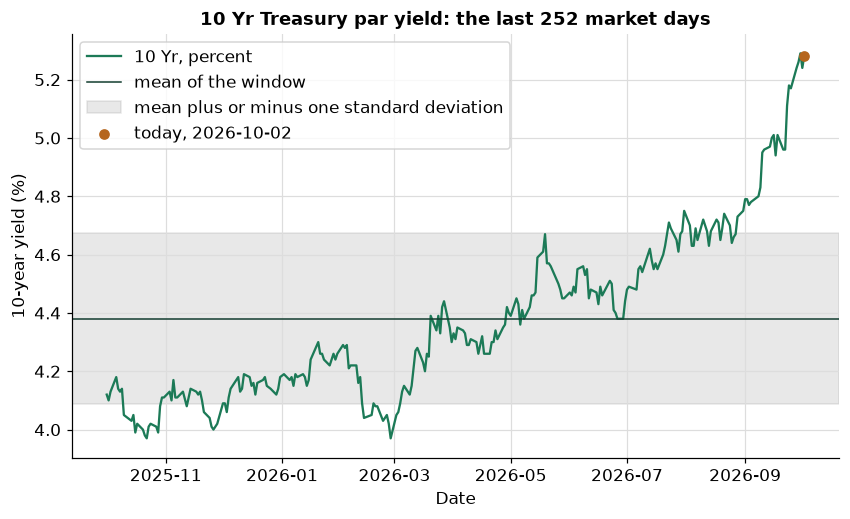

In [10]:
fig, ax = plt.subplots()
ax.plot(window.index, window, color="#1c7a57", label="10 Yr, percent")
# the window's mean, and a band one sample standard deviation either side of it
ax.axhline(window.mean(), color="#123d2f", linewidth=1, label="mean of the window")
ax.axhspan(window.mean() - window.std(), window.mean() + window.std(), color="#8c8c8c", alpha=0.2,
           label="mean plus or minus one standard deviation")
# today's value, the last point of the window
ax.scatter([today], [window.iloc[-1]], color="#b5651d", zorder=3, label=f"today, {today:%Y-%m-%d}")
ax.set_title("10 Yr Treasury par yield: the last 252 market days")
ax.set_xlabel("Date")
ax.set_ylabel("10-year yield (%)")
ax.legend(loc="upper left")
plt.show()

* The red point is today; the grey band is one standard deviation either side of the mean. Today sits above the band, near the top of the line. The chart says where; it says nothing about what comes next.

Q. Draw the window's values as a histogram: the days at or below today in green, the rest in grey.

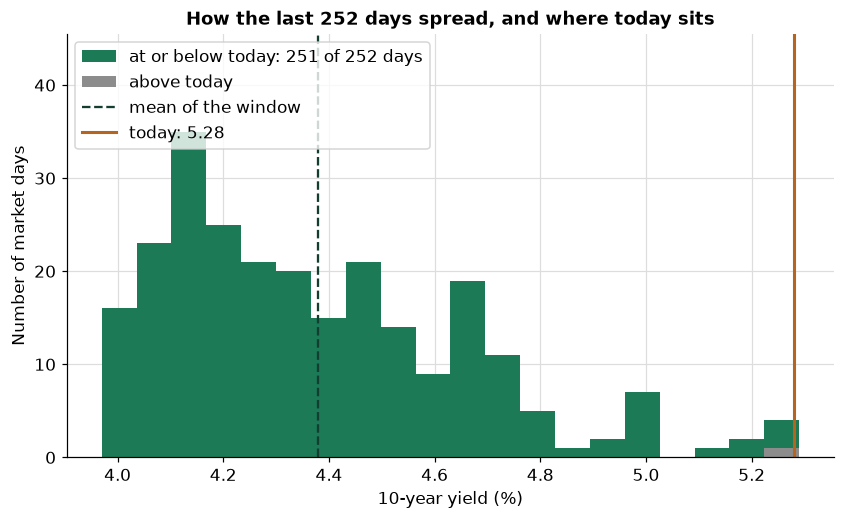

In [11]:
import numpy as np

# the window's values in 20 equal bins; one histogram for the days at or below today's value, one for the days above it
edges = np.histogram_bin_edges(window, bins=20)
today_value = ten_year.iloc[-1]
fig, ax = plt.subplots()
ax.hist(window[window <= today_value], bins=edges, color="#1c7a57",
        label=f"at or below today: {(window <= today_value).sum()} of {len(window)} days")
ax.hist(window[window > today_value], bins=edges, color="#8c8c8c", label="above today")
ax.axvline(window.mean(), color="#123d2f", linestyle="--", label="mean of the window")
ax.axvline(today_value, color="#b5651d", linewidth=2, label=f"today: {today_value:.2f}")
ax.set_axisbelow(True)
ax.set_xlabel("10-year yield (%)")
ax.set_ylabel("Number of market days")
ax.set_title("How the last 252 days spread, and where today sits")
ax.margins(y=0.3)
ax.legend(loc="upper left")
plt.show()

* Each bar counts market days with a yield in that bin. The green bars are the days at or below today's value, so their total is the percentile rank's numerator.
* The dashed line is the mean, which the z-score measures from. The orange line is today.

## 8.2 The Z-Score, Its Window, and Whether Today Is in It

The z-score of today's value against its window:

$$z_t = \frac{x_t - \text{mean of the window}}{\text{sample standard deviation of the window}}$$

The course's definition, from the conventions table: the window is the trailing 252 rows **including today**, the standard deviation is the sample one (`ddof=1`, Excel's `STDEV.S`), there are no partial windows, and a window whose values are all equal (a stale stretch) has no z-score: it is `NaN`, because its standard deviation is 0 and there is nothing to divide by.

A z-score has no unit: a yield in percent and a slope in bp both give plain numbers. That is what lets one table compare a yield, a slope, and a spread.

**A z-score is not a probability.** Turning one into odds needs an assumption about the shape of the distribution, which this course does not make, and a window of 252 rows is one year of one history. This course never turns a z-score into odds.

Q. Add `rolling_zscore` to the module. Read the docstring first.

In [12]:
%%writefile -a marketdata.py


def rolling_zscore(series: pd.Series, window: int = 252) -> pd.Series:
    """Where each value sits in its own trailing window, in standard deviations from the window's mean.

    Units: none (a number of standard deviations). Convention: z_t = (x_t - mean) / sample standard deviation,
    both over the trailing window that includes x_t (window rows, min_periods = window, ddof=1). NaN where the
    window's standard deviation is 0 (a flat, stale stretch). Describes position only; it is not a signal.
    Excel: =STANDARDIZE(B253,AVERAGE(B2:B253),STDEV.S(B2:B253)) filled down
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # the trailing window's mean and sample standard deviation, today included
    mean = series.rolling(window, min_periods=window).mean()
    std = series.rolling(window, min_periods=window).std(ddof=1)
    # a flat window has no spread to measure against
    std = std.where(std != 0)
    return (series - mean) / std

Appending to marketdata.py


* Two rolling statistics over the same window, `min_periods=window` so the first 251 values are `NaN`, and `std.where(std != 0)` to turn a flat window's 0 into `NaN` before dividing. `.where(condition)` keeps the values where the condition is true and puts `NaN` everywhere else.
* The last line of the docstring says it plainly: it describes position only; it is not a signal.

Q. Reload the module and compute the 10 Yr's z-score. Does today's value equal the one worked out by hand in 8.1?

In [13]:
importlib.reload(md)

z_ten_year = md.rolling_zscore(ten_year)
z_by_hand = (ten_year.iloc[-1] - window.mean()) / window.std(ddof=1)
print(f"rolling_zscore on {today:%Y-%m-%d}: {z_ten_year.iloc[-1]:.6f}")
print(f"by hand:                    {z_by_hand:.6f}")
print(f"first z-score: {z_ten_year.first_valid_index():%Y-%m-%d}, row {ten_year.index.get_loc(z_ten_year.first_valid_index()) + 1}; NaN before it: {z_ten_year.isna().sum()}")

rolling_zscore on 2026-10-02: 3.075234
by hand:                    3.075234
first z-score: 2016-01-04, row 252; NaN before it: 251


* The same number, 3.075234. The first z-score is on row 252, the first day with a full window, and the 251 rows before it are `NaN`.

**Today in the window, or not?** The course puts today in its own window. The other choice, also in use, compares today with the 252 rows **before** it, so today's value cannot pull the mean and the standard deviation toward itself.

Q. Compute the z-score the other way, with today left out of its window. Is it the same number?

In [14]:
# the 252 rows before today: rows -253 to -2, today left out
before = ten_year.iloc[-253:-1]
z_today_left_out = (ten_year.iloc[-1] - before.mean()) / before.std(ddof=1)

print(f"today in its window:   {z_ten_year.iloc[-1]:.4f}")
print(f"today left out:        {z_today_left_out:.4f}")
print(f"difference:            {z_today_left_out - z_ten_year.iloc[-1]:.4f}")

today in its window:   3.0752
today left out:        3.1470
difference:            0.0718


* 3.0752 against 3.1470. Same data, same 252 rows of length, a different number. Over the 2026 rows the two definitions differ by up to 0.0843 (on 2026-09-30).
* Neither choice is wrong. What is wrong is a number with no definition beside it. This course includes today, which matches Excel's `STANDARDIZE` over a range that includes today's cell, and says so in the docstring.

Q. Draw both definitions across 2026: today in its window, and today left out.

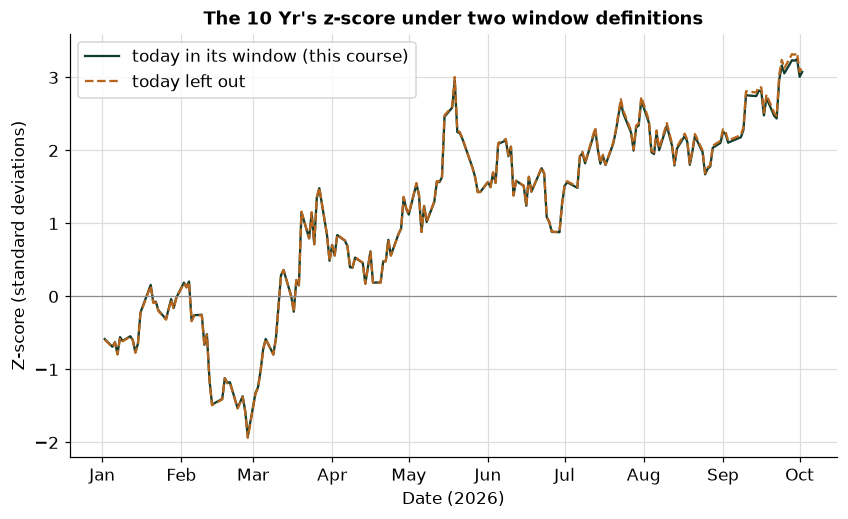

In [15]:
import matplotlib.dates as mdates

# today left out: the mean and standard deviation of the 252 rows that end the day before, so shift each by one row
window_mean = ten_year.rolling(252, min_periods=252).mean()
window_std = ten_year.rolling(252, min_periods=252).std(ddof=1)
z_left_out = (ten_year - window_mean.shift(1)) / window_std.shift(1)

fig, ax = plt.subplots()
ax.plot(z_ten_year.loc["2026"].index, z_ten_year.loc["2026"], color="#123d2f", label="today in its window (this course)")
ax.plot(z_left_out.loc["2026"].index, z_left_out.loc["2026"], color="#b5651d", linestyle="--", label="today left out")
ax.axhline(0, color="#8c8c8c", linewidth=0.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlabel("Date (2026)")
ax.set_ylabel("Z-score (standard deviations)")
ax.set_title("The 10 Yr's z-score under two window definitions")
ax.legend(loc="upper left")
plt.show()

* The two lines follow each other closely and are never the same number. The gap is largest when today is far from the rest of its window, because today pulls the window's mean toward itself when it is included.
* Neither line is wrong. Each has a definition, and the course writes its definition in the docstring.

Q. What does `rolling_zscore` return for a stretch where the value does not change?

In [16]:
# a made-up stale stretch: the same 5.00 percent four days running, then a move and back
dates = pd.bdate_range("2026-09-01", periods=6)
stale = pd.Series([5.0, 5.0, 5.0, 5.0, 5.1, 5.0], index=dates)
stale_table = pd.DataFrame({"value": stale, "z, 3 rows": md.rolling_zscore(stale, window=3)})
# a styled table: .format sets the digits, highlight_null shades the NaN cells (Excel: Format Cells and Conditional Formatting)
(stale_table.style
    .format({"value": "{:.1f}", "z, 3 rows": "{:.2f}"}, na_rep="NaN")
    .format_index("{:%Y-%m-%d}")
    .highlight_null(color="#f3d9b8")
    .set_caption("A stale stretch: the z-score is NaN where the 3-row window holds equal values"))

,value,"z, 3 rows"
2026-09-01,5.0,NaN
2026-09-02,5.0,NaN
2026-09-03,5.0,NaN
2026-09-04,5.0,NaN
2026-09-07,5.1,1.15
2026-09-08,5.0,-0.58


* The windows ending on the third and fourth rows hold three equal values: standard deviation 0, so `NaN` rather than a division by zero. Excel's `STANDARDIZE` over three equal values shows `#NUM!` (tested).

Q. Add the first two tests: the z-score against Excel's `STANDARDIZE` on all 190 reference rows of 2026, for the 10 Yr and for 2s10s, and the flat window.

In [17]:
%%writefile -a test_marketdata.py


def ten_year_and_2s10s() -> dict[str, pd.Series]:
    """The 10 Yr in percent and 2s10s in bp, (10 Yr - 2 Yr) x 100 as the Excel sheet computes it."""
    curve = read_treasury()
    return {"10y": curve["10 Yr"], "2s10s": (curve["10 Yr"] - curve["2 Yr"]) * 100}


def test_zscore_matches_excel_standardize():
    reference = read_reference()
    for name, series in ten_year_and_2s10s().items():
        z = md.rolling_zscore(series, window=252)
        for day, row in reference.iterrows():
            assert z.loc[day] == pytest.approx(row[f"zscore252_{name}"], abs=1e-9), (name, day)


def test_zscore_nan_when_flat():
    dates = pd.bdate_range("2026-09-01", periods=6)
    stale = pd.Series([5.0, 5.0, 5.0, 5.0, 5.1, 5.0], index=dates)
    z = md.rolling_zscore(stale, window=3)
    # windows ending on the third and fourth rows are flat: no z-score
    assert z.iloc[:4].isna().all()
    assert z.iloc[4:].notna().all()

Appending to test_marketdata.py


* `ten_year_and_2s10s` builds the two series the same way as the Excel sheet, so every test today uses the same inputs as Excel did.

Q. Run the tests.

In [18]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_marketdata.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...............................                                          [100%]
31 passed in 1.03s



* `31 passed`: day 7's 29 and today's first two.

## 8.3 The Percentile Rank and Ties

The percentile rank is the share of the window at or below today's value, in percent:

$$\text{rank}_t = 100 \times \frac{\text{number of window values at or below } x_t}{\text{number of values in the window}}$$

Today counts itself, so the rank is above 0 and at most 100: 100 means nothing in the window was higher. **Ties count as at or below.** Yields are quoted to two decimals, so ties are common: the 10 Yr's last 252 days hold only 94 different values.

Q. Ten values, the same ten this course tested in Excel (see Excel Side by Side). What share is at or below 7, and at or below the last value, 8?

In [19]:
# ten values on ten market days; three of them are 7
probe = pd.Series([5, 7, 7, 9, 11, 12, 3, 7, 10, 8], index=pd.bdate_range("2026-09-14", periods=10), dtype=float)

print(f"at or below 7: {(probe <= 7).sum()} of {len(probe)}, {(probe <= 7).mean() * 100:.0f} percent")
print(f"at or below 8: {(probe <= 8).sum()} of {len(probe)}, {(probe <= 8).mean() * 100:.0f} percent")

at or below 7: 5 of 10, 50 percent
at or below 8: 6 of 10, 60 percent


* Five of ten values are at or below 7: the three 7s and the 5 and the 3. The three 7s all count.

Q. pandas' `rank` gives tied values a rank by one of several methods. Which one counts "at or below"?

In [20]:
# rank 1 is the smallest; the three 7s tie for ranks 3, 4, and 5
ranks = pd.DataFrame({method: probe.rank(method=method) for method in ["min", "average", "max"]})
(ranks[probe == 7].drop_duplicates().style
    .format("{:.0f}")
    .format_index("{:%Y-%m-%d}")
    .set_caption("The rank of a 7 among the ten values, by tie method (the three 7s share one row)"))

,min,average,max
2026-09-15,3,4,5


* `min` gives each 7 the lowest of the tied ranks, 3; `average` gives 4; `max` gives 5. Only `max` equals the count of values at or below 7, so `rank(pct=True, method="max")`, which divides by the count, is the percentile rank. (`pct=True` returns each rank as a share of the number of values instead of a whole number.) Excel's two rank functions match the first two: `RANK.EQ(7,A1:A10,1)` returns 3 and `RANK.AVG(7,A1:A10,1)` returns 4 (tested).

**The floating point trap.** 2s10s is a difference of two yields, times 100. Binary arithmetic cannot hold most decimals exactly, so two slopes that are both 32 bp on paper can be stored a hair apart.

Q. Compute two slopes of 32 bp: 4.12 less 3.80, and 4.13 less 3.81, each times 100. Are they equal?

In [21]:
slope_a = (4.12 - 3.80) * 100
slope_b = (4.13 - 3.81) * 100
# repr shows every digit Python stores
print(f"slope_a: {slope_a!r}")
print(f"slope_b: {slope_b!r}")
print(f"equal: {slope_a == slope_b}; slope_a > slope_b: {slope_a > slope_b}")
# rounded to 15 significant digits, the binary tail is gone
print(f"at 15 significant digits: {float(f'{slope_a:.15g}')} and {float(f'{slope_b:.15g}')}")

slope_a: 32.00000000000003
slope_b: 31.999999999999986
equal: False; slope_a > slope_b: True
at 15 significant digits: 32.0 and 32.0


* `32.00000000000003` and `31.999999999999986`: not equal, and the first is the larger. A plain comparison says one 32 bp slope is above the other.
* Excel sees them as a tie. In a sheet with `=(4.12-3.80)*100`, `31`, and `=(4.13-3.81)*100` in A1:A3, `=COUNTIF(A1:A3,"<="&A3)/COUNT(A1:A3)*100` returns 100: all three at or below A3 (tested). `COUNTIF` compares numbers at 15 significant digits (tested for this course on the reference rows).

Q. Does that tail matter on real data? Rank 2s10s with plain pandas, and compare with Excel's `COUNTIF` on the 190 reference rows of 2026. Do the same for the 10 Yr.

In [22]:
# Excel's answers: one row per market day of 2026, every value computed by Excel from the Treasury file
reference = pd.read_csv("course3_excel_reference.csv", parse_dates=["date"], index_col="date", float_precision="round_trip")

for name, series in [("10y", ten_year), ("2s10s", s2s10s)]:
    # the plain pandas rank, values compared exactly as stored
    plain = series.rolling(252, min_periods=252).rank(pct=True, method="max") * 100
    gap = (plain.loc[reference.index] - reference[f"pctrank252_{name}"]).abs()
    print(f"{name:6} plain pandas against COUNTIF: differs on {(gap > 1e-12).sum()} of {len(reference)} rows, by up to {gap.max():.2f} points")

10y    plain pandas against COUNTIF: differs on 0 of 190 rows, by up to 0.00 points
2s10s  plain pandas against COUNTIF: differs on 74 of 190 rows, by up to 5.95 points


* The 10 Yr agrees on every row: its values come straight from the file, two decimals each, so equal yields are stored equal.
* 2s10s differs on **74 of 190 rows**, by up to 5.95 points. Every one of those rows is a tie that Excel counts and plain pandas splits.

Q. Look at the worst day. How many values in its window tie with that day's 2s10s, exactly and at 15 significant digits?

In [23]:
worst_day = (s2s10s.rolling(252, min_periods=252).rank(pct=True, method="max") * 100
             - reference["pctrank252_2s10s"]).abs().idxmax()
worst_window = s2s10s.loc[:worst_day].iloc[-252:]
value = s2s10s.loc[worst_day]

def at_15_digits(v):
    """A number rounded to 15 significant digits, as COUNTIF compares numbers."""
    return float(f"{v:.15g}")

print(f"{worst_day:%Y-%m-%d}: 2s10s stored as {float(value)!r}")
print(f"window values exactly equal to it: {(worst_window == value).sum()}")
print(f"window values equal at 15 significant digits: {(worst_window.map(at_15_digits) == at_15_digits(value)).sum()}")

2026-04-02: 2s10s stored as 51.99999999999996
window values exactly equal to it: 5
window values equal at 15 significant digits: 20


* On 2026-04-02, 2s10s is 52 bp. Only 5 of the window's values are stored exactly equal to it, but 20 are equal at 15 significant digits. Plain pandas gives 28.5714; Excel gives 34.5238.

Q. Draw the tie count on the worst day, found exactly and at 15 significant digits.

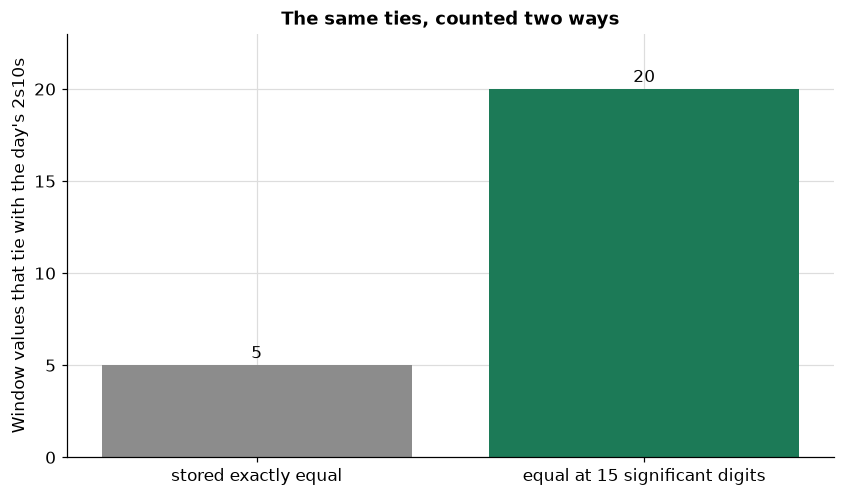

In [24]:
# the two counts from the cell above: window values equal to the day's 2s10s, exactly and at 15 digits
tie_counts = [(worst_window == value).sum(), (worst_window.map(at_15_digits) == at_15_digits(value)).sum()]
fig, ax = plt.subplots()
bars = ax.bar(["stored exactly equal", "equal at 15 significant digits"], tie_counts, color=["#8c8c8c", "#1c7a57"])
ax.bar_label(bars, padding=2)
ax.set_axisbelow(True)
ax.margins(y=0.15)
ax.set_ylabel("Window values that tie with the day's 2s10s")
ax.set_title("The same ties, counted two ways")
plt.show()

* Excel counts the green bar as ties. Plain pandas counts only the grey bar. The ties that pandas misses are values that differ only in the binary tail.

Q. Add `rolling_percentile_rank`. It rounds every value to 15 significant digits first, then ranks.

In [25]:
%%writefile -a marketdata.py


def rolling_percentile_rank(series: pd.Series, window: int = 252) -> pd.Series:
    """The share of the trailing window at or below each value, in percent.

    Units: percent, above 0 up to 100. Convention: 100 x (number of window values at or below x_t) / window,
    over the trailing window that includes x_t (min_periods = window). Ties count as at or below.
    Values are compared at 15 significant digits, as Excel's COUNTIF compares them: in binary arithmetic
    (4.13 - 3.81) x 100 is 31.999999999999986 and (4.12 - 3.80) x 100 is 32.00000000000003, and the two count
    as a tie at 32 bp.
    Excel: =COUNTIF(B2:B253,"<="&B253)/COUNT(B2:B253)*100 filled down. Excel's PERCENTRANK.INC is a
    different measure (values strictly below over n - 1, cut to 3 digits).
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # 15 significant digits, so arithmetic noise in the last binary digit does not break a tie
    rounded = series.map(lambda value: float(f"{value:.15g}"))
    # method="max" gives each value the count of window values at or below it; pct=True divides by the count
    return rounded.rolling(window, min_periods=window).rank(pct=True, method="max") * 100

Appending to marketdata.py


* `float(f"{value:.15g}")` writes the number with 15 significant digits and reads it back, which drops the binary tail. Then `rank(pct=True, method="max")` over the trailing window counts values at or below, and times 100 gives percent.
* The docstring keeps the reason next to the code: the two 32 bp slopes, and the fact that `PERCENTRANK.INC` is a different measure.

Q. Reload, and check it on the probe set and on the reference rows.

In [26]:
importlib.reload(md)

print(f"probe set, last value 8: {md.rolling_percentile_rank(probe, window=10).iloc[-1]:.0f} percent")
for name, series in [("10y", ten_year), ("2s10s", s2s10s)]:
    rank = md.rolling_percentile_rank(series)
    gap = (rank.loc[reference.index] - reference[f"pctrank252_{name}"]).abs()
    print(f"{name:6} rolling_percentile_rank against COUNTIF: differs on {(gap > 1e-12).sum()} of {len(reference)} rows")

probe set, last value 8: 60 percent
10y    rolling_percentile_rank against COUNTIF: differs on 0 of 190 rows
2s10s  rolling_percentile_rank against COUNTIF: differs on 0 of 190 rows


* 60 percent on the probe set, and **0 of 190** on both series. Rounding to 15 significant digits is the whole difference: it is what turns 74 disagreements into none.
* The lesson reaches past today. Any time a computed number is compared for equality, with `==`, a rank, a merge, or a `COUNTIF`, a binary tail can split what should be a tie.

Q. Draw the gap from Excel's `COUNTIF` on every day of 2026, for plain pandas and for `rolling_percentile_rank`.

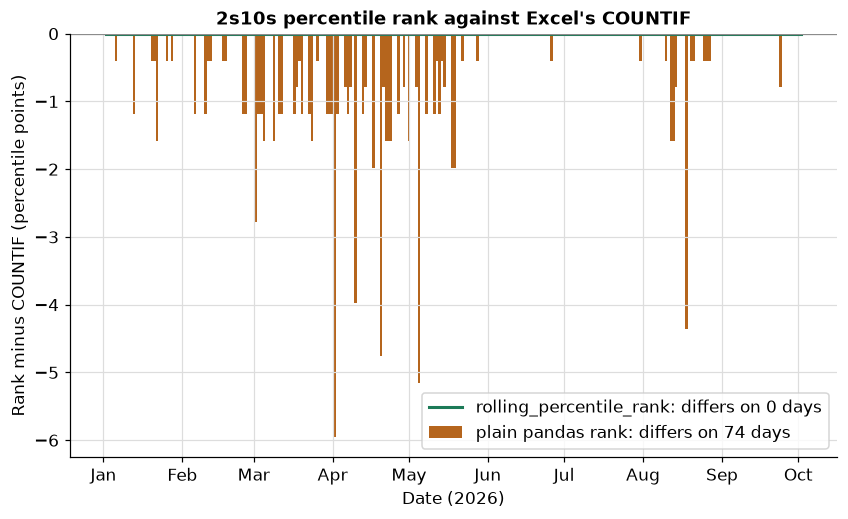

In [27]:
# 2s10s rank minus Excel's COUNTIF, day by day, in percentile points
plain_2s = s2s10s.rolling(252, min_periods=252).rank(pct=True, method="max") * 100
rounded_2s = md.rolling_percentile_rank(s2s10s)
gap_plain_2s = plain_2s.loc[reference.index] - reference["pctrank252_2s10s"]
gap_rounded_2s = rounded_2s.loc[reference.index] - reference["pctrank252_2s10s"]

fig, ax = plt.subplots()
ax.bar(gap_plain_2s.index, gap_plain_2s.values, width=1.0, color="#b5651d",
       label=f"plain pandas rank: differs on {(gap_plain_2s.abs() > 1e-12).sum()} days")
ax.plot(gap_rounded_2s.index, gap_rounded_2s.values, color="#1c7a57", linewidth=2,
        label=f"rolling_percentile_rank: differs on {(gap_rounded_2s.abs() > 1e-12).sum()} days")
ax.axhline(0, color="#8c8c8c", linewidth=0.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlabel("Date (2026)")
ax.set_ylabel("Rank minus COUNTIF (percentile points)")
ax.set_title("2s10s percentile rank against Excel's COUNTIF")
ax.legend(loc="lower right")
plt.show()

* Each orange bar is a day when plain pandas split a tie that Excel counted. The green line is flat at zero: after the 15 digit rounding, the function and Excel agree on every day.

Q. Add the two percentile tests: against Excel's `COUNTIF` on the reference rows, and ties counted as at or below, including the two noisy 32 bp slopes.

In [28]:
%%writefile -a test_marketdata.py


def test_percentile_matches_excel_countif():
    reference = read_reference()
    for name, series in ten_year_and_2s10s().items():
        rank = md.rolling_percentile_rank(series, window=252)
        for day, row in reference.iterrows():
            # Excel: =COUNTIF(window,"<="&x)/COUNT(window)*100, a ratio of whole numbers
            assert rank.loc[day] == pytest.approx(row[f"pctrank252_{name}"], abs=1e-12), (name, day)


def test_percentile_ties_count_as_at_or_below():
    dates = pd.bdate_range("2026-09-01", periods=4)
    values = pd.Series([7.0, 9.0, 7.0, 7.0], index=dates)
    rank = md.rolling_percentile_rank(values, window=4)
    # three of the four values are at or below 7: 75 percent
    assert rank.iloc[-1] == pytest.approx(75.0, abs=1e-12)
    # two slopes of 32 bp with binary noise of opposite sign are still a tie: all three at or below
    noisy = pd.Series([(4.12 - 3.80) * 100, 31.0, (4.13 - 3.81) * 100], index=dates[:3])
    assert noisy.iloc[0] > 32 > noisy.iloc[2]
    assert md.rolling_percentile_rank(noisy, window=3).iloc[-1] == pytest.approx(100.0, abs=1e-12)

Appending to test_marketdata.py


## 8.4 `PERCENTRANK.INC` Is a Different Measure

Excel has a function whose name sounds like the answer: `PERCENTRANK.INC`. Ask an assistant for "the percent of days at or below today" in Excel, and it may suggest it. It measures something else.

On the probe set, `=PERCENTRANK.INC(A1:A10,7)` returns `0.222`, where the share at or below 7 is 50 percent; `=PERCENTRANK.INC(A1:A10,A10)` returns `0.555` for 8, where the share is 60 percent (tested). Tests in Excel for this course found what it computes: the number of values **strictly below**, over n - 1, **cut** (not rounded) to three decimals. On the reference rows that holds for small values too: Excel returns 0.043 where 11 over 251 is 0.0438. `PERCENTRANK.EXC(A1:A10,7)` gives a third answer, `0.272` (tested).

Q. Write that rule in Python. Does it give Excel's two probe values?

In [29]:
import math

def percentrank_inc(values, x):
    """Excel's PERCENTRANK.INC for a value that is in the window: values strictly below x over n - 1, cut to 3 decimals."""
    below = (values < x).sum()
    return math.floor(below / (len(values) - 1) * 1000) / 1000

print(f"PERCENTRANK.INC rule, 7: {percentrank_inc(probe, 7)}   share at or below: {(probe <= 7).mean():.3f}")
print(f"PERCENTRANK.INC rule, 8: {percentrank_inc(probe, 8)}   share at or below: {(probe <= 8).mean():.3f}")

PERCENTRANK.INC rule, 7: 0.222   share at or below: 0.500
PERCENTRANK.INC rule, 8: 0.555   share at or below: 0.600


* `0.222` and `0.555`: Excel's values. For 7, only two values are strictly below (5 and 3), and 2 over 9 is 0.2222, cut to 0.222. The three 7s do not count at all.

Q. On the 190 reference rows, does the rule equal Excel's `PERCENTRANK.INC` column, and how far is it from the percentile rank?

In [30]:
for name, series in [("10y", ten_year), ("2s10s", s2s10s)]:
    # the rule on each day's trailing 252-row window
    mine = pd.Series({day: percentrank_inc(series.loc[:day].iloc[-252:], series.loc[day]) for day in reference.index})
    same = (mine == reference[f"percentrank_inc252_{name}"]).sum()
    # times 100 to put it on the same scale as the percentile rank
    gap = (mine * 100 - reference[f"pctrank252_{name}"]).abs().max()
    print(f"{name:6} equals PERCENTRANK.INC on {same} of {len(reference)} rows; differs from COUNTIF by up to {gap:.2f} points")

10y    equals PERCENTRANK.INC on 190 of 190 rows; differs from COUNTIF by up to 5.02 points
2s10s  equals PERCENTRANK.INC on 190 of 190 rows; differs from COUNTIF by up to 10.13 points


* The rule equals Excel's column on all 190 rows of both series. Times 100, it still differs from the percentile rank by up to 5.02 points on the 10 Yr and 10.13 on 2s10s.
* `PERCENTRANK.INC` is a good function for its own question. It is not the share at or below. The course's Excel formula is `COUNTIF` over `COUNT`.

Q. Draw the two measures for the values 7 and 8 of the ten-value probe set.

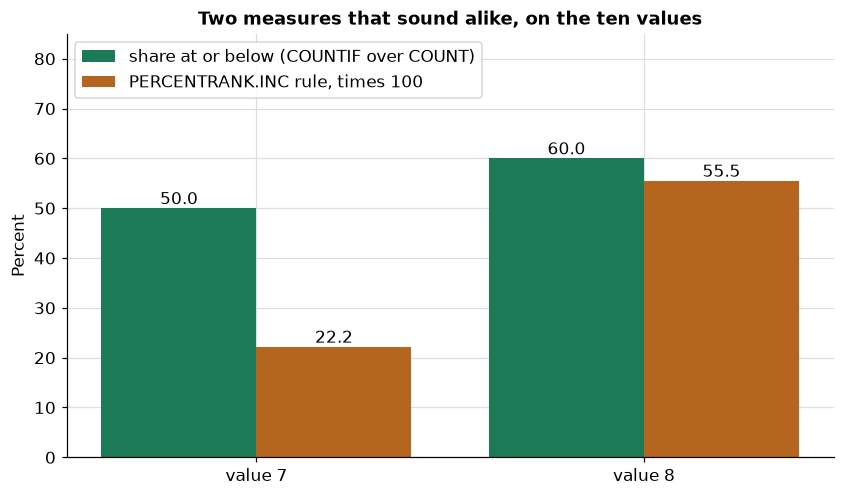

In [31]:
tested_values = [7, 8]
positions = [0, 1]
# the share at or below, and the PERCENTRANK.INC rule times 100, for each value
share_at_or_below = [(probe <= v).mean() * 100 for v in tested_values]
inc_rule = [percentrank_inc(probe, v) * 100 for v in tested_values]

fig, ax = plt.subplots()
bars_share = ax.bar([p - 0.2 for p in positions], share_at_or_below, width=0.4, color="#1c7a57", label="share at or below (COUNTIF over COUNT)")
bars_inc = ax.bar([p + 0.2 for p in positions], inc_rule, width=0.4, color="#b5651d", label="PERCENTRANK.INC rule, times 100")
ax.bar_label(bars_share, fmt="%.1f")
ax.bar_label(bars_inc, fmt="%.1f")
ax.set_xticks(positions, [f"value {v}" for v in tested_values])
ax.set_axisbelow(True)
ax.set_ylim(0, 85)
ax.set_ylabel("Percent")
ax.set_title("Two measures that sound alike, on the ten values")
ax.legend(loc="upper left")
plt.show()

* For 7 the share at or below is 50 and the rule gives 22.2: the three 7s count in the first and not in the second. For 8 the two are 60 and 55.5. Same data, different question.

## 8.5 Both Measures on the 10 Yr and 2s10s for 2026

Q. Put the levels, z-scores, and percentile ranks of both series side by side, and show the last market day of each month of 2026 with day 4's `last_per_period`.

In [32]:
measures = pd.DataFrame({
    "10y_pct": ten_year,
    "10y_z": md.rolling_zscore(ten_year),
    "10y_rank": md.rolling_percentile_rank(ten_year),
    "2s10s_bp": s2s10s,
    "2s10s_z": md.rolling_zscore(s2s10s),
    "2s10s_rank": md.rolling_percentile_rank(s2s10s),
}).loc["2026"]

# the last market day of each month, labelled by its own date
month_ends = md.last_per_period(measures, "ME")
# a styled table: background_gradient shades each rank column from 0 to 100 (Excel: Conditional Formatting, Color Scales)
(month_ends.style
    .format({"10y_pct": "{:.2f}", "10y_z": "{:+.2f}", "10y_rank": "{:.1f}", "2s10s_bp": "{:.1f}", "2s10s_z": "{:+.2f}", "2s10s_rank": "{:.1f}"})
    .format_index("{:%Y-%m-%d}")
    .background_gradient(subset=["10y_rank", "2s10s_rank"], cmap="Greens", vmin=0, vmax=100)
    .set_caption("Month-end levels, z-scores, and percentile ranks of the 10 Yr (%) and 2s10s (bp), 2026"))

,10y_pct,10y_z,10y_rank,2s10s_bp,2s10s_z,2s10s_rank
date,,,,,,
2026-01-30,4.26,-0.02,53.6,74.0,+1.87,100.0
2026-02-27,3.97,-1.92,0.8,59.0,+0.50,75.8
2026-03-31,4.30,+0.49,70.6,51.0,-0.59,27.4
2026-04-30,4.40,+1.20,86.5,52.0,-0.57,36.1
2026-05-29,4.45,+1.43,91.7,47.0,-1.26,7.1
2026-06-30,4.44,+1.26,87.3,30.0,-2.76,2.4
2026-07-31,4.75,+2.69,100.0,47.0,-0.63,21.0
2026-08-31,4.75,+2.10,100.0,41.0,-1.15,15.1
2026-09-30,5.29,+3.25,100.0,41.0,-0.86,23.0


Q. Do the 2026 values equal Excel's `STANDARDIZE` and `COUNTIF` on every reference row?

In [33]:
for name in ["10y", "2s10s"]:
    z_gap = (measures[f"{name}_z"] - reference[f"zscore252_{name}"]).abs().max()
    rank_gap = (measures[f"{name}_rank"] - reference[f"pctrank252_{name}"]).abs().max()
    print(f"{name:6} largest gap: z-score {z_gap:.1e} (STANDARDIZE), percentile rank {rank_gap:.1e} points (COUNTIF)")

10y    largest gap: z-score 1.9e-12 (STANDARDIZE), percentile rank 0.0e+00 points (COUNTIF)
2s10s  largest gap: z-score 7.3e-14 (STANDARDIZE), percentile rank 0.0e+00 points (COUNTIF)


* Z-scores within 1.9e-12 of `STANDARDIZE` (the spec's tolerance is 1e-9: pandas' rolling sums and Excel's direct sums can differ in the last digits). Percentile ranks equal to `COUNTIF` exactly.

Q. Chart 2026: the z-scores of both series in one panel, the percentile ranks in another.

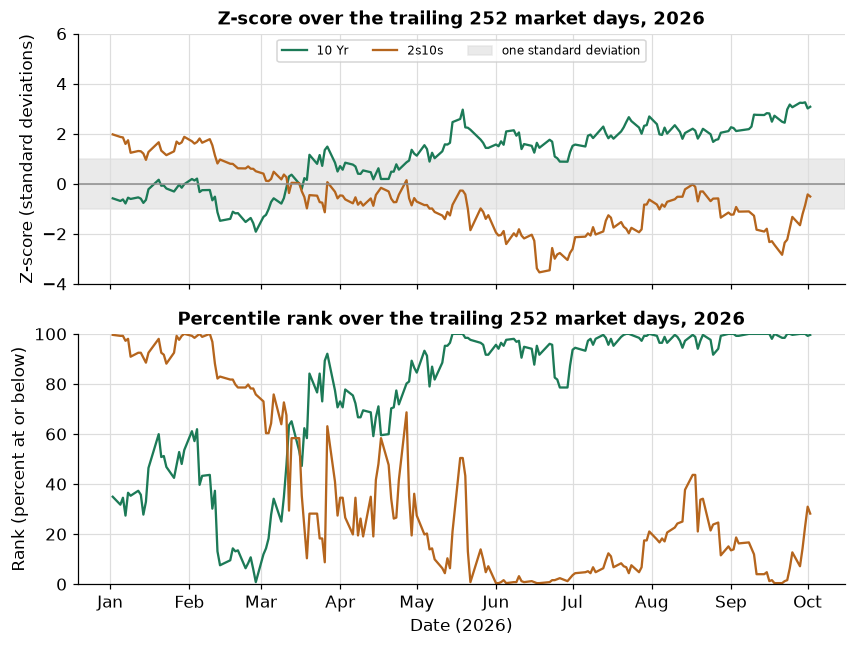

In [34]:
import matplotlib.dates as mdates

fig, (ax_z, ax_rank) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
for column, label, color in [("10y", "10 Yr", "#1c7a57"), ("2s10s", "2s10s", "#b5651d")]:
    ax_z.plot(measures.index, measures[f"{column}_z"], color=color, label=label)
    ax_rank.plot(measures.index, measures[f"{column}_rank"], color=color, label=label)
ax_z.axhline(0, color="#8c8c8c", linewidth=1)
# a grey band one standard deviation either side of zero, only to give the axis a scale
ax_z.axhspan(-1, 1, color="#dddddd", alpha=0.6, label="one standard deviation")
ax_z.set_title("Z-score over the trailing 252 market days, 2026")
ax_z.set_ylabel("Z-score (standard deviations)")
ax_z.set_ylim(-4, 6)
ax_z.legend(loc="upper center", ncols=3, fontsize=8)
ax_rank.set_title("Percentile rank over the trailing 252 market days, 2026")
ax_rank.set_ylabel("Rank (percent at or below)")
ax_rank.set_ylim(0, 100)
# label the months by name, so the dates along the bottom do not run into each other
ax_rank.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax_rank.set_xlabel("Date (2026)")
plt.show()

* The 10 Yr's z-score ran from -1.92 on 2026-02-27 to 3.25 on 2026-09-30. 2s10s ran from -3.54 on 2026-06-18 to 1.97 on 2026-01-02.
* The two panels move together because both measures read the same window. They are not the same: a rank stops at 100, a z-score does not.
* The grey band in the top panel is one standard deviation either side of zero. It is there to give the axis a scale, and it is not a threshold.

Q. Write the description of the last day in one sentence for each series.

In [35]:
last = measures.iloc[-1]
day = measures.index[-1]
print(f"On {day:%Y-%m-%d} the 10 Yr was {last['10y_pct']:.2f} percent, {last['10y_z']:.2f} standard deviations "
      f"{'above' if last['10y_z'] > 0 else 'below'} the mean of its last 252 market days, with {last['10y_rank']:.1f} percent of those days at or below it.")
print(f"On {day:%Y-%m-%d} 2s10s was {last['2s10s_bp']:.1f} bp, {abs(last['2s10s_z']):.2f} standard deviations "
      f"{'above' if last['2s10s_z'] > 0 else 'below'} the mean of its last 252 market days, with {last['2s10s_rank']:.1f} percent of those days at or below it.")

On 2026-10-02 the 10 Yr was 5.28 percent, 3.08 standard deviations above the mean of its last 252 market days, with 99.6 percent of those days at or below it.
On 2026-10-02 2s10s was 45.0 bp, 0.51 standard deviations below the mean of its last 252 market days, with 28.2 percent of those days at or below it.


* Each sentence says where the number sits. Neither says where it goes next, and neither should.

**No lookahead.** A z-score for a past date must be the number you could have computed on that date. Day 7's `assert_no_lookahead` checks it: the output up to a date is the same whether the series stops there or runs on.

Q. Is the 10 Yr's z-score for 2026-06-30 the same if the series stops on 2026-06-30?

In [36]:
full = md.rolling_zscore(ten_year)
stopped = md.rolling_zscore(ten_year.loc[:"2026-06-30"])
print(f"full series:     {float(full.loc['2026-06-30'])!r}")
print(f"stopped there:   {float(stopped.loc['2026-06-30'])!r}")
print(f"every date up to 2026-06-30 identical: {full.loc[:'2026-06-30'].equals(stopped)}")

full series:     1.2639320482185759
stopped there:   1.2639320482185759
every date up to 2026-06-30 identical: True


* Identical to the last digit, on every date. The trailing window only ever looks back.

Q. Add the two no-lookahead tests, with day 7's helper and cut dates, and run the whole file.

In [37]:
%%writefile -a test_marketdata.py


def test_zscore_no_lookahead():
    for series in ten_year_and_2s10s().values():
        assert_no_lookahead(lambda s: md.rolling_zscore(s, window=252), series, CUT_DATES)


def test_percentile_no_lookahead():
    for series in ten_year_and_2s10s().values():
        assert_no_lookahead(lambda s: md.rolling_percentile_rank(s, window=252), series, CUT_DATES)

Appending to test_marketdata.py


In [38]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_marketdata.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...................................                                      [100%]
35 passed in 1.03s



* `35 passed`: the six new tests and every test from days 1 to 7.

## 8.6 Words That Describe and Words That Forecast

A z-score of 3.08 invites a story. The course's rule is to tell only the part the number holds.

<table align="left">
<tr><th align="left">Words that describe (this course uses these)</th><th align="left">Words that forecast or advise (this course never uses these)</th></tr>
<tr><td align="left">3.08 standard deviations above the mean of its last 252 market days</td><td align="left">stretched, extreme, overextended</td></tr>
<tr><td align="left">99.6 percent of the last 252 market days at or below today</td><td align="left">overbought, oversold</td></tr>
<tr><td align="left">the highest since a stated date; the low and high of the window</td><td align="left">cheap, rich, attractive, expensive</td></tr>
<tr><td align="left">up so many bp over the month (day 6)</td><td align="left">due to revert, bound to come back, will fall</td></tr>
<tr><td align="left">the z-score rose from x to y over the month</td><td align="left">a signal, a trigger, a buy, a sell</td></tr>
<tr><td align="left">the window is 252 rows and includes today</td><td align="left">expect, should, likely to</td></tr>
</table>
<br clear="left">

**No threshold.** This course draws no line at a z-score of 2, or at the 90th percentile, as if crossing it meant something. A threshold turns a description into a decision rule, and choosing decision rules is not what this course teaches. If you meet one at work, it is your firm's rule, with your firm's reasons.

**Why the rule is strict.** A z-score compares today with one window of one history. The window's length is a choice, today's place in it is a choice, and the past year may be nothing like the next. The numbers are exact; the story is not in them.

Exercise 3 turns the rule into a function with a test that fails on the forecast words.

## Excel Side by Side

Every line below was typed into Excel (16.0 build 20430, 2026-10-04) by the day's check script, or is in the course's Excel reference file, which Excel computed from the Treasury file.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel (tested)</th><th align="left">Excel returns</th></tr>
<tr><td align="left">Z-score, today in its window</td><td align="left"><code>md.rolling_zscore(ten_year)</code></td><td align="left"><code>=STANDARDIZE(C254,AVERAGE(C3:C254),STDEV.S(C3:C254))</code></td><td align="left">3.075234 on 2026-10-02</td></tr>
<tr><td align="left">Z-score, today left out</td><td align="left">the 252 rows before today</td><td align="left"><code>=STANDARDIZE(C254,AVERAGE(C2:C253),STDEV.S(C2:C253))</code></td><td align="left">3.147044</td></tr>
<tr><td align="left">Z-score of a flat window</td><td align="left"><code>NaN</code></td><td align="left"><code>=STANDARDIZE(A3,AVERAGE(A1:A3),STDEV.S(A1:A3))</code> over 5, 5, 5</td><td align="left"><code>#NUM!</code></td></tr>
<tr><td align="left">Percentile rank, at or below</td><td align="left"><code>md.rolling_percentile_rank(ten_year)</code></td><td align="left"><code>=COUNTIF(C3:C254,"&lt;="&amp;C254)/COUNT(C3:C254)*100</code></td><td align="left">99.603175</td></tr>
<tr><td align="left">The lookalike</td><td align="left"><code>percentrank_inc(window, x)</code></td><td align="left"><code>=PERCENTRANK.INC(C3:C254,C254)</code></td><td align="left">0.996</td></tr>
<tr><td align="left">Ties, lowest rank</td><td align="left"><code>rank(method="min")</code></td><td align="left"><code>=RANK.EQ(7,A1:A10,1)</code> on the probe set</td><td align="left">3</td></tr>
<tr><td align="left">Ties, average rank</td><td align="left"><code>rank(method="average")</code></td><td align="left"><code>=RANK.AVG(7,A1:A10,1)</code></td><td align="left">4</td></tr>
<tr><td align="left">Another lookalike</td><td align="left">not used</td><td align="left"><code>=PERCENTRANK.EXC(A1:A10,7)</code></td><td align="left">0.272</td></tr>
</table>
<br clear="left">

The sheet for the real rows: dates in column A, the 2 Yr in B, the 10 Yr in C, from 2025-09-30 in row 2 to 2026-10-02 in row 254, and 2s10s in D as `=(C2-B2)*100` filled down.

**The z-score in Excel.** In the row of the first full window, type `=STANDARDIZE(C253,AVERAGE(C2:C253),STDEV.S(C2:C253))`. `STANDARDIZE` takes the value, the mean, and the standard deviation, and returns (value - mean) / standard deviation. `AVERAGE` and `STDEV.S` over the 252 cells ending on today's row are the window. Fill it down: the relative references move one row each row, so every row gets its own trailing window that ends on itself, exactly what `rolling(252)` does. The course's reference sheet was built that way, and its values equal `rolling_zscore` to within 1.9e-12.

**Today left out.** Shift both ranges up one row so they stop the row before today: `=STANDARDIZE(C254,AVERAGE(C2:C253),STDEV.S(C2:C253))` on the last row gives 3.147044, against 3.075234 with today in. Same data, different definition, different number, in Excel as in Python.

**The percentile rank in Excel.** `=COUNTIF(C3:C254,"<="&C254)/COUNT(C3:C254)*100`. `COUNTIF` counts the cells that meet a condition; the condition `"<="&C254` is the text `<=` joined to today's value, so it counts the window's values at or below today, ties included. `COUNT` counts the numbers in the window, 252. Times 100 gives percent: 99.603175 for the 10 Yr, 28.174603 for 2s10s. `COUNTIF` compares at 15 significant digits, which is why `rolling_percentile_rank` rounds first.

**The lookalike.** `=PERCENTRANK.INC(C3:C254,C254)` returns 0.996 for the 10 Yr and 0.266 for 2s10s: strictly below over n - 1, cut to three decimals. Use it when that is the question; for the share at or below, use `COUNTIF` over `COUNT`.

Q. Do Python's numbers equal the values Excel returned on 2026-10-02?

In [39]:
# Excel's values on the last row, from the day's check script
excel = {"10y z, today in": 3.075234405274332, "10y z, today left out": 3.1470437882795372,
         "10y COUNTIF rank": 99.60317460317461, "2s10s z, today in": -0.5109000465103897,
         "2s10s COUNTIF rank": 28.174603174603174}
python = {"10y z, today in": md.rolling_zscore(ten_year).iloc[-1], "10y z, today left out": z_today_left_out,
          "10y COUNTIF rank": md.rolling_percentile_rank(ten_year).iloc[-1], "2s10s z, today in": md.rolling_zscore(s2s10s).iloc[-1],
          "2s10s COUNTIF rank": md.rolling_percentile_rank(s2s10s).iloc[-1]}
for name in excel:
    print(f"{name:22} Excel {excel[name]:12.6f}   Python {python[name]:12.6f}   gap {abs(excel[name] - python[name]):.1e}")

10y z, today in        Excel     3.075234   Python     3.075234   gap 4.6e-13
10y z, today left out  Excel     3.147044   Python     3.147044   gap 3.6e-15
10y COUNTIF rank       Excel    99.603175   Python    99.603175   gap 0.0e+00
2s10s z, today in      Excel    -0.510900   Python    -0.510900   gap 1.1e-15
2s10s COUNTIF rank     Excel    28.174603   Python    28.174603   gap 0.0e+00


* Every gap is below 1e-9, and the ranks are equal: the same definitions, written two ways.

## Save the Day with Git

Today's step: `git grep`, to find every place a pattern appears in the tracked files. Before you change a default, such as a window of 252 rows, find every function that has one.

Q. Make the work folder a repository, and commit today's two files.

In [40]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [41]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course3_08_7gl8csjo and nowhere else


In [42]:
# commit the module and the tests, then show the log
!git -C "{work}" add marketdata.py test_marketdata.py
!git -C "{work}" commit -q -m "Add rolling_zscore and rolling_percentile_rank with six tests" -m "Both use a trailing window that includes today; the percentile rank compares values at 15 significant digits, as Excel's COUNTIF does."
!git -C "{work}" log --oneline

e233ae5 Add rolling_zscore and rolling_percentile_rank with six tests


Q. Where does the module open a rolling window?

In [43]:
# -n prints line numbers; -- marketdata.py limits the search to that file
!git -C "{work}" grep -n "rolling(" -- marketdata.py

marketdata.py:413:    vol = changes_bp.rolling(window, min_periods=window).std(ddof=1)
marketdata.py:434:    mean = series.rolling(window, min_periods=window).mean()
marketdata.py:435:    std = series.rolling(window, min_periods=window).std(ddof=1)
marketdata.py:460:    return rounded.rolling(window, min_periods=window).rank(pct=True, method="max") * 100


* 4 lines: day 7's volatility and today's mean, standard deviation, and rank. Each opens a window of `window` rows with `min_periods=window`, so all 4 follow the same convention.

Q. Which functions take a window, and what is each default?

In [44]:
!git -C "{work}" grep -n "window: int = " -- marketdata.py

marketdata.py:398:def rolling_vol_bp(changes_bp: pd.Series, window: int = 63, annualise: bool = False) -> pd.Series:
marketdata.py:420:def rolling_zscore(series: pd.Series, window: int = 252) -> pd.Series:
marketdata.py:441:def rolling_percentile_rank(series: pd.Series, window: int = 252) -> pd.Series:


* `rolling_vol_bp` defaults to 63 rows, `rolling_zscore` and `rolling_percentile_rank` to 252. A change to "the" default window is really a change to 3 lines, and `git grep` is how you find them before you start, not after a test fails.
* `git grep` searches only what Git tracks. The data files and `bondmath.py` are untracked copies, so it never wanders into them.

## Bring It Home

Add today's functions and tests to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code, with the course's `.venv` active.

**Step 1.** Go to your folder and open the two files.

```powershell
Set-Location "$HOME\projects\my_bondmath"
code marketdata.py
code test_marketdata.py
```

**Step 2.** Paste the two `%%writefile -a marketdata.py` cells (sections 8.2 and 8.3), without their first line, at the end of `marketdata.py`, and the three `%%writefile -a test_marketdata.py` cells at the end of `test_marketdata.py`. Keep two blank lines between functions. Save both. The tests read `course3_excel_reference.csv`; it has been in your folder since day 6.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_marketdata.py
```

```
35 passed
```

**Step 4.** Read the change, find the windows, and commit.

```powershell
git diff --stat
git grep -n "rolling(" -- marketdata.py
git add marketdata.py test_marketdata.py
git commit -m "Add rolling_zscore and rolling_percentile_rank with six tests"
git log --oneline -3
```

**If a test fails**, compare your files with the cells. A percentile test that fails on 2s10s alone usually means the 15 significant digit rounding line is missing.

**In Colab**, download `marketdata.py` and `test_marketdata.py` from the work folder under `/tmp` in the file browser.

## You Can Now

* Say where today's value sits in its own window three ways: the distance in bp, the z-score, and the percentile rank.
* Compute a z-score over a trailing window that includes today, and show that leaving today out changes the number.
* Compute a percentile rank that counts ties as at or below, and explain why values are compared at 15 significant digits.
* Explain why `PERCENTRANK.INC` is not the share at or below, with `COUNTIF` over `COUNT` as the Excel formula that is.
* Prove a window function uses no future data with a no-lookahead test.
* Describe a level without forecasting it.
* Find every window in a module with `git grep` before changing a default.

Tomorrow, day 9, builds the curve measures this notebook computed by hand: slopes and butterflies, with their signs, `slope_bp` and `butterfly_bp`, and the rolling z-scores of each.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Exercises 1 and 2 use a second set of series: the 5 Yr and 5s30s. Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the curve and defines `check`, a small function that marks your answers.

In [45]:
# the Treasury file: one row per market day, yields in percent; round_trip reads every number exactly as written
curve = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"], index_col="date", float_precision="round_trip")
ten_year = curve["10 Yr"]
# 2s10s in bp: the 10 Yr less the 2 Yr, times 100, the way the Excel reference sheet computes it (day 9 makes it a function)
s2s10s = ((curve["10 Yr"] - curve["2 Yr"]) * 100).rename("2s10s")


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

### Exercise 1

Q. Compute the 252-row z-score and percentile rank of the 5 Yr, `curve["5 Yr"]`, with your module. Store the values on the last day, 2026-10-02, in **ex1_z** and **ex1_pct**.

In [46]:
ex1_z = ...
ex1_pct = ...

In [47]:
check("Exercise 1 the z-score", ex1_z, 2.7959990869553395)
check("Exercise 1 the percentile rank", ex1_pct, 99.60317460317461)

Exercise 1 the z-score: not attempted yet
Exercise 1 the percentile rank: not attempted yet


### Exercise 2

Q. Make 5s30s in bp, `(curve["30 Yr"] - curve["5 Yr"]) * 100`, and compute its z-score and percentile rank over **63** rows, about three months. Store the values on 2026-10-02 in **ex2_z** and **ex2_pct**. Then compute them over 252 rows too, and say in a comment how the window changes the description.

In [48]:
ex2_z = ...
ex2_pct = ...
# how the window changes the description:

In [49]:
check("Exercise 2 the 63-row z-score", ex2_z, -1.0784129299830423)
check("Exercise 2 the 63-row percentile rank", ex2_pct, 23.809523809523807)

Exercise 2 the 63-row z-score: not attempted yet
Exercise 2 the 63-row percentile rank: not attempted yet


### Exercise 3

Q. Add a function to your module. `describe_position(z, pct)` returns one sentence from a fixed template: `Today's value is 0.51 standard deviations below the mean of its window, and 28.2 percent of the window is at or below it.` Round `z` to 2 decimals and `pct` to 1; when `z` rounds to 0, say `at the mean of its window` instead. Write the docstring first. Raise `ValueError` if `z` is NaN or `pct` is not above 0 and at most 100. Then add a test, `test_describe_position_only_describes`, that checks the sentence for `(-0.51, 28.2)`, checks that it contains none of a set of forecast words (`will`, `expect`, `should`, `cheap`, `rich`, `stretched`, `signal`, `revert`, `overbought`, `oversold`, `buy`, `sell`, `due`), and checks both errors. Run pytest, reload the module, and store `md.describe_position(-0.51, 28.2)` in **ex3_text**.

The module already imports `math` (day 7). Write the function in the cell that starts with `%%writefile -a marketdata.py` and the test in the one that starts with `%%writefile -a test_marketdata.py`, and run each of those cells once.

In [50]:
%%writefile -a marketdata.py


# Exercise 3: write describe_position(z, pct) below this line

Appending to marketdata.py


In [51]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_describe_position_only_describes() below this line

Appending to test_marketdata.py


In [52]:
# run pytest, reload the module, then call your function
ex3_text = ...

In [53]:
check("Exercise 3 the sentence", ex3_text, "Today's value is 0.51 standard deviations below the mean of its window, and 28.2 percent of the window is at or below it.")

Exercise 3 the sentence: not attempted yet


### Exercise 4: AI check

You ask an AI assistant for a z-score function, and you give it the docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
Where each value sits in its own trailing window, in standard deviations from the window's mean.

    Units: none (a number of standard deviations). Convention: z_t = (x_t - mean) / sample standard deviation,
    both over the trailing window that includes x_t (window rows, min_periods = window, ddof=1). Describes
    position only.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns numbers of a believable size, and contains one bug.

In [54]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def zscore_from_assistant(series, window=252):
    """Where each value sits in its own trailing window, in standard deviations from the window's mean.

    Units: none (a number of standard deviations). Convention: z_t = (x_t - mean) / sample standard deviation,
    both over the trailing window that includes x_t (window rows, min_periods = window, ddof=1). Describes
    position only.
    """
    # the mean and the sample standard deviation
    mean = series.mean()
    std = series.std(ddof=1)
    z = (series - mean) / std
    # no partial windows: the first window - 1 values stay empty
    z.iloc[: window - 1] = float("nan")
    return z

Q. Predict before you run the next cell: is the z-score for 2026-06-30 the same when the series stops on 2026-06-30 as when it runs to the end of the file?

In [55]:
full = zscore_from_assistant(ten_year)
stopped = zscore_from_assistant(ten_year.loc[:"2026-06-30"])
print(f"2026-06-30, full series:   {full.loc['2026-06-30']:.4f}")
print(f"2026-06-30, stopped there: {stopped.loc['2026-06-30']:.4f}")

2026-06-30, full series:   1.4157
2026-06-30, stopped there: 1.4886


Q. Test the function against its docstring before you trust it: the same no-lookahead check as day 7's helper, written out.

In [56]:
# the test, written from the docstring before the code is trusted: cut the series at each date, and the
# z-scores up to that date must not change when the later rows are added back
full = zscore_from_assistant(ten_year)
for cut in ["2025-04-17", "2026-06-30", "2026-09-30"]:
    cut_result = zscore_from_assistant(ten_year.loc[:cut])
    assert full.loc[:cut].equals(cut_result), f"the z-scores up to {cut} change when later rows are added: lookahead"
print("No lookahead: every z-score uses only its own date and the rows before it")

AssertionError: the z-scores up to 2025-04-17 change when later rows are added: lookahead

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store whether the fixed function's z-scores up to 2026-06-30 are unchanged when the series stops there, in **ex4_no_lookahead**, and its z-score on the last day in **ex4_last_z**.

In [57]:
# fix the function above and run the test again, then store the two answers
ex4_no_lookahead = ...
ex4_last_z = ...

In [58]:
check("Exercise 4 no lookahead", ex4_no_lookahead, True)
check("Exercise 4 the last z-score", ex4_last_z, 3.075234405273874)

Exercise 4 no lookahead: not attempted yet
Exercise 4 the last z-score: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```